### Prospectivity Map

####  *AUTHOR:* Ehsan Farahbakhsh
####  *CONTACT:* e.farahbakhsh@sydney.edu.au
####  *DATE last modified:* 16/09/2025

This notebook uses the machine learning model trained in notebook `04_predictive_modelling` to analyse the probability of finding porphyry deposits within continental landmasses over time.

In addition to generating animations that visualise the temporal evolution of probability, it also allows users to create a global prospectivity map, 
along with corresponding uncertainty maps, for porphyry mineralisation.

We begin by importing the required libraries:

In [1]:
# Import libraries
from ipywidgets import interact
import os

import cartopy.crs as ccrs
import cmcrameri.cm as ccm
import gplately
import joblib
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.kernel_ridge import KernelRidge
from tqdm import tqdm

# Note: Ensure the 'lib' folder is located in the same folder as this notebook
from lib.prospectivity_map import *
from lib.feature_extraction import *
from lib.reconstruction_coregistration import *
from lib.predictive_modelling import *
from lib.plot import *

# Load configuration parameters (e.g., paths, model names)
from parameters import parameters

2026-05-17 11:28:43 - gplately - ERROR - Failed to import PyGMT. PyGMT requires Python>=3.11.
2026-05-17 11:28:46 - gplately - ERROR - Failed to import PyGMT. PyGMT requires Python>=3.11.


### Setup

As defined in `parameters.py`, the cell below configures the analysis parameters and specifies the paths to input/output files and directories. You can also specify the number of cores to use by setting an appropriate value for the `n_jobs` variable at the end of the cell.

**Note:** You can modify the analysis settings directly in `parameters.py`, located in the same folder as this notebook. The file is structured as a dictionary; look for keys such as `timespan` and `temporal_resolution` to adjust their values as needed.

In [2]:
# Set up temporal analysis parameters
temporal_resolution = parameters["temporal_resolution"]
time_min = parameters["timespan"]["min"] # Youngest time to analyse
time_max = parameters["timespan"]["max"] # Oldest time to analyse
# Create an array of time steps for analysis (e.g., 0, 1, 2, ... Ma)
time_steps = range(time_min, time_max + temporal_resolution, temporal_resolution)

buffer_distance = parameters["buffer_distance"]
grid_resolution = parameters["grid_resolution"]

# Directory paths for inputs and outputs
plate_model_dir = parameters["plate_model_dir"]
inputs_dir = parameters["inputs_dir"]
outputs_dir = parameters["outputs_dir"]
buffer_zones_dir = parameters["buffer_zones_dir"]
ml_dir = parameters["ml_dir"]
coastline_prob_grids_dir = parameters["coastline_prob_grids_dir"]
coastline_entropy_grids_dir = parameters["coastline_entropy_grids_dir"]
coastline_vote_variance_grids_dir = parameters["coastline_vote_variance_grids_dir"]
coastline_prob_maps_dir = parameters["coastline_prob_maps_dir"]
coastline_entropy_maps_dir = parameters["coastline_entropy_maps_dir"]
coastline_vote_variance_maps_dir = parameters["coastline_vote_variance_maps_dir"]

# Data filenames
subduction_data_filename = parameters["subduction_data_filename"]
coastlines_filename = parameters["coastlines_filename"]
coastline_coords_filename = parameters["coastline_coords_filename"]
coastline_data_filename = parameters["coastline_data_filename"]
coastline_prob_filename = parameters["coastline_prob_filename"]
deposit_coords_recon_all_filename = parameters["deposit_coords_recon_all_filename"]
coastline_prob_present_day_filename = parameters["coastline_prob_present_day_filename"]
coastline_prob_present_day_grid_filename = parameters["coastline_prob_present_day_grid_filename"]
coastline_entropy_present_day_grid_filename = parameters["coastline_entropy_present_day_grid_filename"]
coastline_vote_variance_present_day_grid_filename = parameters["coastline_vote_variance_present_day_grid_filename"]
deposit_coords_recon_filename = parameters["deposit_coords_recon_filename"]

model_rf_calibrated_filename = parameters["model_rf_calibrated_filename"]
robust_scaler_filename = parameters["robust_scaler_filename"]

# Construct full directory paths
ml_dir = os.path.join(outputs_dir, ml_dir)
buffer_zones_dir = os.path.join(outputs_dir, buffer_zones_dir)
coastline_prob_grids_dir = os.path.join(ml_dir, coastline_prob_grids_dir)
coastline_entropy_grids_dir = os.path.join(ml_dir, coastline_entropy_grids_dir)
coastline_vote_variance_grids_dir = os.path.join(ml_dir, coastline_vote_variance_grids_dir)
coastline_prob_maps_dir = os.path.join(ml_dir, coastline_prob_maps_dir)
coastline_entropy_maps_dir = os.path.join(ml_dir, coastline_entropy_maps_dir)
coastline_vote_variance_maps_dir = os.path.join(ml_dir, coastline_vote_variance_maps_dir)

# Construct full file paths
subduction_data_filename = os.path.join(outputs_dir, subduction_data_filename)
coastlines_filename = os.path.join(inputs_dir, coastlines_filename)
coastline_coords_filename = os.path.join(outputs_dir, coastline_coords_filename)
coastline_data_filename = os.path.join(outputs_dir, coastline_data_filename)
coastline_prob_filename = os.path.join(ml_dir, coastline_prob_filename)
deposit_coords_recon_all_filename = os.path.join(outputs_dir, deposit_coords_recon_all_filename)
coastline_prob_present_day_filename = os.path.join(ml_dir, coastline_prob_present_day_filename)
coastline_prob_present_day_grid_filename = os.path.join(ml_dir, coastline_prob_present_day_grid_filename)
coastline_entropy_present_day_grid_filename = os.path.join(ml_dir, coastline_entropy_present_day_grid_filename)
coastline_vote_variance_present_day_grid_filename = os.path.join(ml_dir, coastline_vote_variance_present_day_grid_filename)
deposit_coords_recon_filename = os.path.join(outputs_dir, deposit_coords_recon_filename)
buffer_zone_present_filename = os.path.join(buffer_zones_dir, "craton_buffer_0000Ma.geojson")

model_rf_calibrated_filename = os.path.join(ml_dir, model_rf_calibrated_filename)
robust_scaler_filename = os.path.join(ml_dir, robust_scaler_filename)

# Paths to different types of grids
agegrid_dir = os.path.join(inputs_dir, "SeafloorAge")
crusthick_dir = os.path.join(inputs_dir, "CrustalThickness")

# Number of cores to be used for running this notebook
n_jobs = 20

The cell below loads the necessary files to create the `PlateReconstruction` and `PlateTopologies` objects, which will later be used for reconstruction and generating visualisations.

In [3]:
# # # STELLAR4A plate motion model
# # rotation_model = plate_model_dir+"/CombinedRotations.rot"

# # topology_features = [
# #     plate_model_dir+"/Deforming_Networks_Active.gpml",
# #     plate_model_dir+"/Deforming_Networks_Inactive.gpml",
# #     plate_model_dir+"/Feature_Geometries.gpml",
# #     # plate_model_dir+"/Flat_Slabs.gpml", # Including this file may introduce artifacts, so it is recommended to exclude it when creating the PlateReconstruction object.
# #     plate_model_dir+"/Plate_Boundaries.gpml",
# # ]

# # static_polygons = plate_model_dir+"/Global_EarthByte_GPlates_PresentDay_StaticPlatePolygons.gpml"
# # coastlines = plate_model_dir+"/Global_coastlines_low_res.gpml"
# # continents = plate_model_dir+"/Global_EarthByte_GPlates_PresentDay_ContinentsAndArcs.gpml"
# # COBs = plate_model_dir+"/Global_EarthByte_GeeK07_COBLineSegments_2019_v1.gpml"

# # plate_reconstruction = PlateReconstruction(
# #     rotation_model=rotation_model,
# #     topology_features=topology_features,
# #     static_polygons=static_polygons,
# # )

# # gplot = PlotTopologies(
# #     plate_reconstruction=plate_reconstruction,
# #     coastlines=coastlines,
# #     continents=continents,
# #     COBs=COBs,
# # )

# # # Define map projection (Mollweide provides a good global view) and central meridian
# # projection = ccrs.Mollweide(central_longitude=60)
# central_meridian = 0


# import glob

# input_directory = r'C:\Users\hshi9735\OneDrive - The University of Sydney (Students)\PhD_1_Notebooks\Deposits_Rev2\shirmard25'

# # Load both rotation files
# rotation_filenames = glob.glob(os.path.join(input_directory, '*.rot')) # Include both rot files
# rotation_model = pygplates.RotationModel(rotation_filenames)

# # Load static polygons
# static_polygons = pygplates.FeatureCollection(os.path.join(input_directory, 'static_polygons.gpmlz'))
# COBs = os.path.join(input_directory, 'COBfile_1800_0.gpml')  # Use updated COB file

# # Load topology files and combine them into a single FeatureCollection
# topology_filenames = [
#     os.path.join(input_directory, '250-0_plate_boundaries.gpml'),
#     os.path.join(input_directory, '410-250_plate_boundaries.gpml'),
#     os.path.join(input_directory, '1800-1000_plate_boundaries.gpml'),
#     os.path.join(input_directory, '1000-410_plate-boundaries.gpml'),  # Corrected file name
#     os.path.join(input_directory, '1000-410-Convergence.gpml'),
#     os.path.join(input_directory, '1000-410-Divergence.gpml'),
#     os.path.join(input_directory, '1000-410-Transforms.gpml'),
#     os.path.join(input_directory, 'TopologyBuildingBlocks.gpml'),
# ]

# # Create an empty list to hold all the features
# all_topology_features = []

# # Load each file and append its features to the list
# for topology_filename in topology_filenames:
#     fc = pygplates.FeatureCollection(topology_filename)
#     all_topology_features.extend(fc)

# # Create a single FeatureCollection from the combined features
# topology_features = pygplates.FeatureCollection(all_topology_features)

# # Optionally load other geological features if needed
# continents = pygplates.FeatureCollection(os.path.join(input_directory, 'shapes_continents.gpmlz'))
# COBs = pygplates.FeatureCollection(os.path.join(input_directory, 'COBfile_1800_0.gpml'))
# coastlines = pygplates.FeatureCollection(os.path.join(input_directory, 'shapes_coasts.gpmlz'))

# # Now you can proceed with your reconstruction and plotting...
# plate_reconstruction = PlateReconstruction(
#     rotation_model=rotation_model,
#     topology_features=topology_features,
#     static_polygons=static_polygons,
# )

# gplot = PlotTopologies(
#     plate_reconstruction=plate_reconstruction,
#     coastlines=coastlines,
#     continents=continents,
#     COBs=COBs,
# )
# # subduction_data = pd.read_csv(subduction_data_filename) # Load feature values
# # deposit_coords = pd.read_csv(deposit_coords_filename) # Load deposit coordinates and weights

# # Define map projection (Mollweide provides a good global view)
# projection = ccrs.Mollweide(central_longitude=60)

In [4]:
import pygplates
import glob
import os

use_local_files = True

if use_local_files:
    # Method 1: manually point to files
    #input_directory = 'shirmard25'
    #input_directory = r'./shirmard25'  # Raw string to avoid issues with backslashes
    input_directory_rot = r'C:\Users\hshi9735\OneDrive - The University of Sydney (Students)\PhD_1_Notebooks\Deposits_Rev2\Muller25_1.8_Ga_OMR_NNR_TPW_ref_frame\optimisation'
    input_directory = r'C:\Users\hshi9735\OneDrive - The University of Sydney (Students)\PhD_1_Notebooks\Deposits_Rev2\Muller25_1.8_Ga_OMR_NNR_TPW_ref_frame'
    input_directory_nc = r'C:\Users\hshi9735\OneDrive - The University of Sydney (Students)\PhD_1_Notebooks\Deposits_Rev2\Muller25_1.8_Ga_OMR_NNR_TPW_ref_frame\Cao2024-Optimised-COB-Masks'
    # Load both rotation files
    rotation_filenames = glob.glob(os.path.join(input_directory_rot, '*.rot')) # Include all rot files
    rotation_model = pygplates.RotationModel(rotation_filenames)

    # Load static polygons
    static_polygons = pygplates.FeatureCollection(os.path.join(input_directory, 'static_polygons.gpmlz'))
    COBs = os.path.join(input_directory, 'COBfile_1800_0.gpml')  # Use updated COB file

    # Load topology files and combine them into a single FeatureCollection
    topology_filenames = [
        os.path.join(input_directory, '250-0_plate_boundaries.gpml'),
        os.path.join(input_directory, '410-250_plate_boundaries.gpml'),
        os.path.join(input_directory, '1800-1000_plate_boundaries.gpml'),
        os.path.join(input_directory, '1000-410-plate-boundaries.gpml'),  # Corrected file name
        os.path.join(input_directory, '1000-410-Convergence.gpml'),
        os.path.join(input_directory, '1000-410-Divergence.gpml'),
        os.path.join(input_directory, '1000-410-Transforms.gpml'),
        os.path.join(input_directory, 'TopologyBuildingBlocks.gpml'),
    ]

    # Create an empty list to hold all the features
    all_topology_features = []

    # Load each file and append its features to the list
    for topology_filename in topology_filenames:
        fc = pygplates.FeatureCollection(topology_filename)
        all_topology_features.extend(fc)

    # Create a single FeatureCollection from the combined features
    topology_features = pygplates.FeatureCollection(all_topology_features)

    # Optionally load other geological features if needed
    #continent_contour_features = pygplates.FeatureCollection(os.path.join(input_directory_nc, 'continent_contour_features.gpmlz'))
    continents = pygplates.FeatureCollection(os.path.join(input_directory, 'shapes_continents.gpmlz'))

    COBs = pygplates.FeatureCollection(os.path.join(input_directory, 'COBfile_1800_0.gpml'))
    shapes_coasts = pygplates.FeatureCollection(os.path.join(input_directory, 'shapes_coasts.gpmlz'))

    # Create PlateReconstruction model
    
    # model = gplately.PlateReconstruction(rotation_model=rotation_model, 
    #                                      topology_features=topology_features, 
    #                                      static_polygons=static_polygons)

    plate_reconstruction = gplately.PlateReconstruction(rotation_model=rotation_model,
                                         anchor_plate_id= 14, 
                                         topology_features=topology_features, 
                                         static_polygons=static_polygons)

    gplot = gplately.PlotTopologies(plate_reconstruction,
                                        coastlines = shapes_coasts,
                                        continents =continents,
                                        COBs =COBs,
                                        #time=1800,
                                        anchor_plate_id= 14,
                                       )
    # Now you can proceed with your reconstruction and plotting...


### Points within Continental Landmasses

To generate a single global prospectivity map showing mineralisation probability at present-day coordinates using the trained model, we must reconstruct the points within the present-day continental landmass and track how their probabilities change over time. The process begins by generating a regular grid of points within the present-day continental landmass and reconstructing their locations over time using a plate motion model, retaining only those that fall within the buffer zones representing arc–backarc environments. Running the cell below results in a dataframe containing the latitude, longitude, time, and plate ID of the points across the continental landmasses through time.

In [5]:
if os.path.isfile(coastline_coords_filename):
    coastline_coords = pd.read_csv(coastline_coords_filename)
else:
    # Reconstruct the points within the present-day continental landmass through time
    coastline_coords = reconstruct_coastline_nodes(
        coastlines=coastlines_filename, # Present-day coastlines
        coastlines_recon=continents, # Present-day reconstructable coastlines
        buffer_zone_present=buffer_zone_present_filename,
        resolution= grid_resolution, # The distance between the points
        buffer_zones_dir=buffer_zones_dir,
        time_steps=time_steps,
        plate_reconstruction=plate_reconstruction,
        coastlines_recon_dir = outputs_dir + '/coastlines_recon',
        output_filename=coastline_coords_filename,
        verbose=True,
    )

This section generates an interactive map that displays the reconstructed points together with seafloor age and plate boundaries—including mid-ocean ridges and transform faults—at a selected time.

In [6]:
projection = ccrs.Mollweide(central_longitude=0)

In [10]:
@interact
def show_map(time=time_steps):
    gplot.time = time    
    
    # Load seafloor age grid for the specified geological time
    agegrid_filename =  "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(time)
    agegrid_file = os.path.join(agegrid_dir, agegrid_filename)    
    agegrid = gplately.grids.read_netcdf_grid(agegrid_file)
    
    fig = plt.figure(figsize=(16, 12))
    ax = plt.axes(
        projection=projection,
        facecolor=(plt.cm.colors.to_rgba("azure", alpha=0.5))
    )

    # Plot seafloor age as background
    im = gplot.plot_grid(ax, agegrid.data, cmap=ccm.lapaz_r, vmin=0, vmax=230, alpha=0.7, zorder=1)
    # Plot continental areas in dark grey
    gplot.plot_coastlines(ax, facecolor="darkgray", edgecolor="none", zorder=2)
    # Plot plate motion vectors (arrows showing plate movement direction)
    gplot.plot_plate_motion_vectors(ax, spacingX=10, spacingY=10, normalise=True, alpha=0.1, zorder=3)

    # Load and plot buffer zones for the specified geological time
    # buffer_zones_t_filename = f"buffer_zones_{time}Ma.geojson"
    # buffer_zones_t_filename = os.path.join(buffer_zones_dir, buffer_zones_t_filename)
    # buffer_zones_t = gpd.read_file(buffer_zones_t_filename)

    # buffer_zones_t.plot(
    #     ax=ax,
    #     transform=ccrs.PlateCarree(),
    #     facecolor="palegreen",
    #     edgecolor="none",
    #     alpha=0.7,
    #     zorder=4,
    # )

    # Plot grid points
    coastline_coords_t = coastline_coords[coastline_coords["age (Ma)"] == time]

    gplot.plot_ridges(ax, color="dimgray", linewidth=1.5, zorder=5)
    gplot.plot_transforms(ax, color="dimgray", linewidth=1.5, zorder=5)

    ax.scatter(
        coastline_coords_t["lon"],
        coastline_coords_t["lat"],
        transform=ccrs.PlateCarree(),
        marker=".",
        c="red",
        s=1,
        alpha=0.5,
        zorder=6
    )
    
    gplot.plot_trenches(ax, color="k", alpha=0.3, zorder=7)
    gplot.plot_subduction_teeth(ax, spacing=0.05, color="k", alpha=0.3, zorder=8)

    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, x_inline=False, linewidth=1, color="gray", alpha=0.3, linestyle="--", zorder=9)

    ax.text(0.49,-0.03, "60°E", transform=ax.transAxes, fontsize=16)
    ax.text(0.46,-0.03, "0°", transform=ax.transAxes, fontsize=16)
    ax.text(0.40,-0.025, "60°W", transform=ax.transAxes, fontsize=16)
    
    gl.top_labels=False
    gl.bottom_labels=False
    
    gl.xlabel_style = {"size": 16}
    gl.ylabel_style = {"size": 16}
    
    cb = fig.colorbar(im, orientation="horizontal", shrink=0.4, pad=0.06, extend="max")
    cb.set_label("Seafloor Age (Ma)", fontsize=16, labelpad=10)
    cb.set_ticks([0, 50, 100, 150, 200])
    cb.ax.tick_params(labelsize=16)

    # Dummy handle to trigger custom handler
    trench_handle = Line2D([], [], color="black")
    
    # Add custom handles
    custom_handles = [
        Patch(facecolor="darkgray", edgecolor="none"),
        # Patch(facecolor="palegreen", edgecolor="none", alpha=0.7),
        trench_handle,
        Line2D([0], [0], color="dimgray", lw=2),
        Line2D([0], [0], marker=".", markerfacecolor="red", markeredgecolor="none", markersize=10, linestyle="None")
    ]
    custom_labels = [
        "Continental Crust",
        # "Target Back-Arc Envs",
        "Trench Lines",
        "Mid-Ocean Ridges/\nTransform Faults",
        "Target Points within\nBack-Arc Envs and\nContinental Landmass",
    ]

    # Draw legend
    ax.legend(custom_handles, custom_labels, fontsize=16, loc="lower left", bbox_to_anchor=(0, -0.3),
              handler_map={trench_handle: HandlerTrenchLine()})

    ax.set_title(f"{time} Ma", fontsize=25, y=1.04)
        
    plt.show()

interactive(children=(Dropdown(description='time', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, …

### Coregistration

This code block performs co-registration by finding the closest trench point to each point in the previously created point set within the buffer zones. It then assigns the feature values of the nearest trench point to each of the points, along with the distance between them. The `run_coregister_crustal_thickness` function is specifically designed to coregister points with crustal thickness grids.

In [8]:
# if os.path.isfile(coastline_data_filename):
#     coastline_data = pd.read_csv(coastline_data_filename)
# else:
#     # The feature values calculated using the "01_feature_extraction" notebook will be loaded
#     subduction_data = pd.read_csv(subduction_data_filename)

#     coastline_data = run_coregister_point_data(
#         point_data=coastline_coords,
#         subduction_data=subduction_data,
#         keep_index=True,
#         n_jobs=n_jobs,
#         verbose=True,
#     )
    
#     coastline_data = run_coregister_crustal_thickness(
#         point_data=coastline_data,
#         input_dir=crusthick_dir,
#         output_filename=coastline_data_filename,
#         n_jobs=n_jobs,
#         verbose=True,
#     )

### Calculate Probability, Entropy, and Vote Variance

We apply the trained model in notebook `04_predictive_modelling` to the previously generated points located within buffer zones that encompass arc–backarc environments, in order to estimate:

- **Mineralisation Probability**: The model's confidence that geological conditions are favourable for deposit formation.  
- **Entropy**: A measure of prediction uncertainty (high entropy indicates greater model uncertainty).  
- **Vote Variance**: The variability among decision trees (high variance suggests conflicting results between trees).  

The resulting predictions are saved as global grids, highlighting where mineralisation is most likely and where the model is more or less confident. These grids make it possible to visualise variations in mineralisation probability, helping to identify both potential exploration targets and areas of uncertainty in the predictions.

In [9]:
coastline_data = pd.read_csv(coastline_data_filename)

OSError: [Errno 22] Invalid argument

In [ ]:
if os.path.isfile(coastline_prob_filename):
    print(f"Probabilities have already been calculated and saved in {coastline_prob_filename}\nLoading ...")
    coastline_prob = pd.read_csv(coastline_prob_filename)
else:
    # Load model and scaler
    model_rf_calibrated = joblib.load(model_rf_calibrated_filename)
    model_rf_calibrated.n_jobs = n_jobs
    robust_scaler = joblib.load(robust_scaler_filename)

    if "valid" in coastline_data.columns:
        # Filter valid rows
        coastline_data = coastline_data[coastline_data["valid"]].copy()

    # Scale feature values using the same scaler as training
    selected_features = model_rf_calibrated.feature_names_in_
    coastline_scaled = robust_scaler.transform(coastline_data[selected_features])
    coastline_scaled = pd.DataFrame(coastline_scaled, columns=selected_features)

    # Calculate probability and entropy values for all points
    # Entropy quantifies uncertainty in model predictions
    probs = model_rf_calibrated.predict_proba(coastline_scaled)[:, 1].ravel()

    # Prepare final DataFrame
    columns_prob = [
        "index_x",
        "lon",
        "lat",
        "present_lon",
        "present_lat",
        "age (Ma)",
    ]
    
    coastline_prob = coastline_data[columns_prob].copy()
    coastline_prob["probability"] = probs

    entropies = calculate_entropy(probs)
    coastline_prob["entropy"] = entropies
    
    # Calculate vote variance
    # Vote variance shows disagreement among decision trees
    chunk_size = 100000  # Adjust based on available memory
    n_samples = coastline_scaled.shape[0]
    n_chunks = (n_samples // chunk_size) + (1 if n_samples % chunk_size != 0 else 0)  # Ensure last chunk is included
    
    for i in tqdm(range(n_chunks)):
        start_idx = i * chunk_size
        end_idx = min((i + 1) * chunk_size, n_samples)
    
        X_chunk = coastline_scaled.iloc[start_idx:end_idx]
        
        # Calculate vote variance for the chunk
        vote_variances_chunk = calculate_tree_vote_variance(model_rf_calibrated.estimator, X_chunk.values)
        
        # Ensure that the chunk size matches the number of rows being processed
        if len(vote_variances_chunk) != (end_idx - start_idx):
            raise ValueError(f"Mismatch in size: {len(vote_variances_chunk)} vs. {end_idx - start_idx}")
        
        # Assign the result to the appropriate slice of the dataframe
        coastline_prob.loc[start_idx:end_idx-1, "vote_variance"] = vote_variances_chunk
    
    # Export rows with calculated metrics
    print(f"Saving the metrics as a CSV file: {coastline_prob_filename}")
    coastline_prob.to_csv(coastline_prob_filename, index=False)

# Create probability grids
if os.path.exists(coastline_prob_grids_dir):
    print(f"Probability grids are located in {coastline_prob_grids_dir}")
else:
    os.makedirs(coastline_prob_grids_dir, exist_ok=True)

    create_grids(
        data=coastline_prob_filename,
        output_dir=coastline_prob_grids_dir,
        times=time_steps,
        resolution= grid_resolution,
        extent=(-180, 180, -90, 90),
        interpolation=True,
        threads=n_jobs,
        verbose=True,
        column="probability",
        filename_format="coastline_probability_grid_{}Ma.nc",
    )

# Create entropy grids
if os.path.exists(coastline_entropy_grids_dir):
    print(f"Entropy grids are located in {coastline_entropy_grids_dir}")
else:
    os.makedirs(coastline_entropy_grids_dir, exist_ok=True)

    create_grids(
        data=coastline_prob_filename,
        output_dir=coastline_entropy_grids_dir,
        times=time_steps,
        resolution= grid_resolution,
        extent=(-180, 180, -90, 90),
        interpolation=True,
        threads=n_jobs,
        verbose=True,
        column="entropy",
        filename_format="coastline_entropy_grid_{}Ma.nc",
    )

# Create vote variance grids
if os.path.exists(coastline_vote_variance_grids_dir):
    print(f"Vote variance grids are located in {coastline_vote_variance_grids_dir}")
else:
    os.makedirs(coastline_vote_variance_grids_dir, exist_ok=True)

    create_grids(
        data=coastline_prob_filename,
        output_dir=coastline_vote_variance_grids_dir,
        times=time_steps,
        resolution= grid_resolution,
        extent=(-180, 180, -90, 90),
        interpolation=True,
        threads=n_jobs,
        verbose=True,
        column="vote_variance",
        filename_format="coastline_vote_variance_grid_{}Ma.nc",        
    )

### Probability Maps

This section generates an interactive probability map that displays mineralisation probability along trench lines within the continental landmasses, alongside known mineral occurrences. It also plots seafloor age and plate boundaries, including mid-ocean ridges and transform faults, at a selected time. The visualisation highlights spatial patterns, showing how mineralisation probability relates to tectonic features, and temporal evolution, showing how favourable conditions migrate through time.

In [11]:
central_meridian = 0
projection = ccrs.Mollweide(central_longitude=0)

In [12]:
@interact
def show_map(time=time_steps):
    gplot.time = time # Set reconstruction time
    fig = plot(
        gplot=gplot,
        grid=os.path.join(
            coastline_prob_grids_dir,
            f"coastline_probability_grid_{time:0.0f}Ma.nc", # Mineralisation probability grid
        ),
        grid_type="probability",
        background_grid=os.path.join(
            agegrid_dir,
            "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(time), # Seafloor age grid
        ),
        positives=deposit_coords_recon_all_filename, # Reconstructed location of known mineral occurrences
        projection=projection,
        time=time,
        central_meridian=central_meridian,
    )

interactive(children=(Dropdown(description='time', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, …

The cell below generates a full sequence of mineralisation probability maps through geological time and compiles them into a time-lapse animation, illustrating how the modelled probability of mineralisation changes over time.

In [13]:
coastlines = shapes_coasts

In [14]:
# Generate all probability maps and create animation
if os.path.exists(coastline_prob_maps_dir):
    print(f"Probability maps are located in {coastline_prob_maps_dir}")
else:
    os.makedirs(coastline_prob_maps_dir, exist_ok=True)

    # Create maps in parallel for efficiency
    with Parallel(
        n_jobs=n_jobs,
        verbose=True,
        pre_dispatch="all",
        batch_size=int(len(time_steps) // n_jobs) + 1,
    ) as parallel:

        # Define output filename for each time step
        output_filenames = [
            os.path.join(coastline_prob_maps_dir, f"coastline_probability_map_{t:0.0f}Ma.png")
            for t in time_steps
        ]

        parallel(
            delayed(plot_parallel)(
                rotation_model,
                topology_features,
                static_polygons,
                coastlines,
                continents,
                COBs,
                grid=os.path.join(
                    coastline_prob_grids_dir,
                    f"coastline_probability_grid_{t:0.0f}Ma.nc",
                ),
                grid_type="probability",
                background_grid=os.path.join(
                    agegrid_dir,
                    "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(t), # Seafloor age grid
                ),
                positives=deposit_coords_recon_all_filename,
                projection=projection,
                time=t,
                output_filename=o,
                central_meridian=central_meridian,
            )
            for t, o in zip(time_steps, output_filenames)
        )

    # Create an animation showing the evolution of mineralisation probability
    # Animation reveals temporal patterns in geological processes
    output_filename = os.path.join(ml_dir, "coastline_probability_animation.mp4")
    create_animation(
        image_filenames=output_filenames[::-1],
        output_filename=output_filename,
        fps=10,
        bitrate="5000k",
    )

Probability maps are located in outputs\ml\coastline_prob_maps


In [15]:
import re

files = os.listdir(coastline_prob_maps_dir)
time_steps_found = set()

for file in files:
    match = re.match(r'coastline_probability_map_(\d+)Ma\.png', file)
    if match:
        time_step = int(match.group(1))
        time_steps_found.add(time_step)

all_time_steps = set(range(0, time_max+1, 1))
missing_time_steps = sorted(list(all_time_steps - time_steps_found))

print(missing_time_steps)

[]


In [28]:
with Parallel(
    n_jobs=n_jobs,
    verbose=True,
    pre_dispatch="all",
    batch_size=int(len(missing_time_steps) // n_jobs) + 1,
) as parallel:

    # Create all plots
    output_filenames = [
        os.path.join(coastline_prob_maps_dir, f"coastline_probability_map_{t:0.0f}Ma.png")
        for t in missing_time_steps
    ]

    parallel(
        delayed(plot_parallel)(
            rotation_model,
            topology_features,
            static_polygons,
            coastlines,
            continents,
            COBs,
            grid=os.path.join(
                coastline_prob_grids_dir,
                f"coastline_probability_grid_{t:0.0f}Ma.nc",
            ),
            grid_type="probability",
            background_grid=os.path.join(
                agegrid_dir,
                "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(t), # Seafloor age grid,
            ),
            positives=deposit_coords_recon_all_filename,
            projection=projection,
            time=t,
            output_filename=o,
            central_meridian=central_meridian,
        )
        for t, o in zip(missing_time_steps, output_filenames)
    )

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   4 out of   4 | elapsed:  1.1min finished


In [23]:
from PIL import Image

bad_files = []

for f in output_filenames:
    try:
        img = Image.open(f)
        img.verify()
    except Exception as e:
        print("Bad file:", f)
        bad_files.append(f)

print("Total bad files:", len(bad_files))

Total bad files: 0


In [26]:
from PIL import Image
import os

bad_files = []

for f in output_filenames:
    if not os.path.exists(f) or os.path.getsize(f) == 0:
        bad_files.append((f, "missing or empty"))
        continue
    try:
        with Image.open(f) as img:
            img.verify()
    except Exception as e:
        bad_files.append((f, str(e)))

print(bad_files)

[('outputs\\ml\\coastline_prob_maps\\coastline_probability_map_872Ma.png', 'missing or empty'), ('outputs\\ml\\coastline_prob_maps\\coastline_probability_map_1365Ma.png', 'missing or empty'), ('outputs\\ml\\coastline_prob_maps\\coastline_probability_map_1415Ma.png', 'missing or empty'), ('outputs\\ml\\coastline_prob_maps\\coastline_probability_map_1649Ma.png', 'missing or empty')]


In [29]:
output_filenames = [
    os.path.join(coastline_prob_maps_dir, f"coastline_probability_map_{t:0.0f}Ma.png")
    for t in time_steps
]

# Create animation
output_filename = os.path.join(ml_dir, "coastline_probability_animation.mp4")
create_animation(
    image_filenames=output_filenames[::-1],
    output_filename=output_filename,
    fps=10,
    bitrate="5000k",
)

### Entropy Maps

This section generates an interactive entropy map along trench lines within the continental landmasses, combined with known mineral occurrences. It also displays seafloor age and plate boundaries—including mid-ocean ridges and transform faults—at a chosen time step.

Entropy is a statistical measure of uncertainty in the model's probability predictions:

- **Low entropy (≈ 0):** The model is confident. Predictions lean strongly toward either a high or low probability of mineralisation.
- **High entropy (≈ 1):** The model is uncertain. Probabilities cluster near 50%, indicating ambiguity about whether conditions favour or hinder deposit formation.

Entropy maps allow you to explore how spatial uncertainty in mineralisation changes through geological time. By sliding across different time steps, you can visualise regions where the model's predictions are most confident versus where they remain uncertain.

In [19]:
@interact
def show_map(time=time_steps):
    gplot.time = time # Set reconstruction time
    fig = plot(
        gplot=gplot,
        grid=os.path.join(
            coastline_entropy_grids_dir,
            f"coastline_entropy_grid_{time:0.0f}Ma.nc", # Entropy grid
        ),
        grid_type="entropy",
        background_grid=os.path.join(
            agegrid_dir,
            "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(time), # Seafloor age grid
        ),
        positives=deposit_coords_recon_all_filename, # Reconstructed location of known mineral occurrences
        projection=projection,
        time=time,
        central_meridian=central_meridian,
    )

interactive(children=(Dropdown(description='time', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, …

The cell below generates a complete sequence of entropy maps through geological time and compiles them into a time-lapse animation. This visualisation shows how entropy evolves over time, providing an intuitive way to communicate model uncertainty across Earth's history. Such animations are especially useful for identifying when and where the predictive model is most stable or most variable.

In [20]:
# Generate all entropy maps and create animation
if os.path.exists(coastline_entropy_maps_dir):
    print(f"Entropy maps are located in {coastline_entropy_maps_dir}")
else:
    os.makedirs(coastline_entropy_maps_dir, exist_ok=True)

    # Create maps in parallel for efficiency
    with Parallel(
        n_jobs=n_jobs,
        verbose=True,
        pre_dispatch="all",
        batch_size=int(len(time_steps) // n_jobs) + 1,
    ) as parallel:

        # Define output filename for each time step
        output_filenames = [
            os.path.join(coastline_entropy_maps_dir, f"coastline_entropy_map_{t:0.0f}Ma.png")
            for t in time_steps
        ]

        parallel(
            delayed(plot_parallel)(
                rotation_model,
                topology_features,
                static_polygons,
                coastlines,
                continents,
                COBs,
                grid=os.path.join(
                    coastline_entropy_grids_dir,
                    f"coastline_entropy_grid_{t:0.0f}Ma.nc",
                ),
                grid_type="entropy",
                background_grid=os.path.join(
                    agegrid_dir,
                    f"seafloor_age_{t:0.0f}Ma.nc",
                ),
                positives=deposit_coords_recon_all_filename,
                projection=projection,
                time=t,
                output_filename=o,
                central_meridian=central_meridian,
            )
            for t, o in zip(time_steps, output_filenames)
        )

    # Create an animation showing the changes in entropy through geological time
    output_filename = os.path.join(ml_dir, "coastline_entropy_animation.mp4")
    create_animation(
        image_filenames=output_filenames[::-1],
        output_filename=output_filename,
        fps=10,
        bitrate="5000k",
    )

Entropy maps are located in outputs\ml\coastline_entropy_maps


In [21]:
import re

files = os.listdir(coastline_entropy_maps_dir)
time_steps_found = set()

for file in files:
    match = re.match(r'coastline_entropy_map_(\d+)Ma\.png', file)
    if match:
        time_step = int(match.group(1))
        time_steps_found.add(time_step)

all_time_steps = set(range(0, time_max+1, 1))
missing_time_steps = sorted(list(all_time_steps - time_steps_found))

print(missing_time_steps)

[]


In [22]:
with Parallel(
    n_jobs=n_jobs,
    verbose=True,
    pre_dispatch="all",
    batch_size=int(len(missing_time_steps) // n_jobs) + 1,
) as parallel:

    # Create all plots
    output_filenames = [
        os.path.join(coastline_entropy_maps_dir, f"coastline_entropy_map_{t:0.0f}Ma.png")
        for t in missing_time_steps
    ]

    parallel(
        delayed(plot_parallel)(
            rotation_model,
            topology_features,
            static_polygons,
            coastlines,
            continents,
            COBs,
            grid=os.path.join(
                coastline_entropy_grids_dir,
                f"coastline_entropy_grid_{t:0.0f}Ma.nc",
            ),
            grid_type="entropy",
            background_grid=os.path.join(
                agegrid_dir,
                "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(t), # Seafloor age grid,
            ),
            positives=deposit_coords_recon_all_filename,
            projection=projection,
            time=t,
            output_filename=o,
            central_meridian=central_meridian,
        )
        for t, o in zip(missing_time_steps, output_filenames)
    )

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.


In [23]:
output_filenames = [
    os.path.join(coastline_entropy_maps_dir, f"coastline_entropy_map_{t:0.0f}Ma.png")
    for t in time_steps
]

# Create animation
output_filename = os.path.join(ml_dir, "coastline_entropy_animation.mp4")
create_animation(
    image_filenames=output_filenames[::-1],
    output_filename=output_filename,
    fps=10,
    bitrate="5000k",
)

### Vote Variance Maps

Vote variance maps illustrate model disagreement—showing where different iterations of a predictive model produce varying estimates of mineralisation likelihood. Each tree in the Random Forest casts a vote for a given location, predicting either the presence, absence, or probability of mineralisation. The vote variance is then calculated as the statistical variance of these votes across all trees.

High vote variance indicates less agreement between models, highlighting uncertainty in the geological features driving mineralisation. Conversely, low variance reflects model consensus and suggests more stable predictive signals.

The following code segment generates an interactive plot of a vote variance map for a selected geological time, enabling users to explore model agreement and disagreement in predicted mineral prospectivity through time.

In [24]:
@interact
def show_map(time=time_steps):
    gplot.time = time # Set reconstruction time
    fig = plot(
        gplot=gplot,
        grid=os.path.join(
            coastline_vote_variance_grids_dir,
            f"coastline_vote_variance_grid_{time:0.0f}Ma.nc", # Vote variance grid
        ),
        grid_type="vote variance",
        background_grid=os.path.join(
            agegrid_dir,
            "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(time), # Seafloor age grid
        ),
        positives=deposit_coords_recon_all_filename, # Reconstructed location of known mineral occurrences
        projection=projection,
        time=time,
        central_meridian=central_meridian,
    )

interactive(children=(Dropdown(description='time', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, …

The cell below generates a full sequence of vote variance maps across geological time and compiles them into a time-lapse animation. This visualisation highlights where model consensus on mineralisation is strong or weak at each time step.

In [25]:
# Generate all vote variance maps and create animation
if os.path.exists(coastline_vote_variance_maps_dir):
    print(f"Vote variance maps are located in {coastline_vote_variance_maps_dir}")
else:
    os.makedirs(coastline_vote_variance_maps_dir, exist_ok=True)

    # Create maps in parallel for efficiency
    with Parallel(
        n_jobs=16,
        verbose=True,
        pre_dispatch="all",
        batch_size=int(len(time_steps) // n_jobs) + 1,
    ) as parallel:

        # Define output filename for each time step
        output_filenames = [
            os.path.join(coastline_vote_variance_maps_dir, f"coastline_vote_variance_map_{t:0.0f}Ma.png")
            for t in time_steps
        ]

        parallel(
            delayed(plot_parallel)(
                rotation_model,
                topology_features,
                static_polygons,
                coastlines,
                continents,
                COBs,
                grid=os.path.join(
                    coastline_vote_variance_grids_dir,
                    f"coastline_vote_variance_grid_{t:0.0f}Ma.nc",
                ),
                grid_type="vote variance",
                background_grid=os.path.join(
                    agegrid_dir,
                    "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(t), # Seafloor age grid
                ),
                positives=deposit_coords_recon_all_filename,
                projection=projection,
                time=t,
                output_filename=o,
                central_meridian=central_meridian,
            )
            for t, o in zip(time_steps, output_filenames)
        )

    # Create an animation showing the changes in vote variance through geological time
    output_filename = os.path.join(ml_dir, "coastline_vote_variance_animation.mp4")
    create_animation(
        image_filenames=output_filenames[::-1],
        output_filename=output_filename,
        fps=10,
        bitrate="5000k",
    )

Vote variance maps are located in outputs\ml\coastline_vote_variance_maps


In [26]:
import re

files = os.listdir(coastline_vote_variance_maps_dir)
time_steps_found = set()

for file in files:
    match = re.match(r'coastline_vote_variance_map_(\d+)Ma\.png', file)
    if match:
        time_step = int(match.group(1))
        time_steps_found.add(time_step)

all_time_steps = set(range(0, time_max+1, 1))
missing_time_steps = sorted(list(all_time_steps - time_steps_found))

print(missing_time_steps)

[]


In [27]:
with Parallel(
    n_jobs=n_jobs,
    verbose=True,
    pre_dispatch="all",
    batch_size=int(len(missing_time_steps) // n_jobs) + 1,
) as parallel:

    # Create all plots
    output_filenames = [
        os.path.join(coastline_vote_variance_maps_dir, f"coastline_vote_variance_map_{t:0.0f}Ma.png")
        for t in missing_time_steps
    ]

    parallel(
        delayed(plot_parallel)(
            rotation_model,
            topology_features,
            static_polygons,
            coastlines,
            continents,
            COBs,
            grid=os.path.join(
                coastline_vote_variance_grids_dir,
                f"coastline_vote_variance_grid_{t:0.0f}Ma.nc",
            ),
            grid_type="vote variance",
            background_grid=os.path.join(
                agegrid_dir,
                "Cao2024_SEAFLOOR_AGE_grid_{:.2f}Ma.nc".format(t), # Seafloor age grid,
            ),
            positives=deposit_coords_recon_all_filename,
            projection=projection,
            time=t,
            output_filename=o,
            central_meridian=central_meridian,
        )
        for t, o in zip(missing_time_steps, output_filenames)
    )

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.


In [28]:
output_filenames = [
    os.path.join(coastline_vote_variance_maps_dir, f"coastline_vote_variance_map_{t:0.0f}Ma.png")
    for t in time_steps
]

# Create animation
output_filename = os.path.join(ml_dir, "coastline_vote_variance_animation.mp4")
create_animation(
    image_filenames=output_filenames[::-1],
    output_filename=output_filename,
    fps=10,
    bitrate="5000k",
)

### Trend of Average Probability, Entropy, and Vote Variance

Here, we calculate the average probability values greater than 0.5 for each of the points generated at the beginning of this notebook over time. By filtering out low-probability predictions (probability ≤ 0.5), we focus on promising sites, resulting in a clean dataset that highlights the most probable and geologically reliable locations for porphyry mineralisation at present-day coordinates.

In [14]:
if os.path.isfile(coastline_prob_present_day_filename):
    coastline_prob_present_day = pd.read_csv(coastline_prob_present_day_filename)
else:
    # Filter for high-probability locations
    coastline_prob_high = coastline_prob[coastline_prob["probability"] > 0.8]
    # Average probability, entropy, and vote variance for each unique location index
    coastline_prob_high_mean = coastline_prob_high.groupby("index_x")[["probability", "entropy", "vote_variance"]].mean().reset_index()
    present_day_coords = coastline_data[["index_x", "present_lon", "present_lat"]].drop_duplicates(subset="index_x")
    # Merge the averaged probabilities with present-day coordinates
    coastline_prob_present_day = pd.merge(coastline_prob_high_mean, present_day_coords, on="index_x", how="left")
    coastline_prob_present_day = coastline_prob_present_day[["index_x", "present_lon", "present_lat", "probability", "entropy", "vote_variance"]]
    # Save output
    coastline_prob_present_day.to_csv(coastline_prob_present_day_filename, index=False)

This section visualises how the average predicted probability of porphyry mineralisation for points within the continental landmasses varies over geological time, and relates these probabilities to both the number of known deposits at different ages (shown as a histogram) and the average value of a selected feature associated with those probabilities. This highlights how the feature evolves through time.

It also provides the option to plot the uncertainty envelope for the average trends by calculating the standard deviation of values at each time step. The curves are smoothed to emphasise trends, and dual y-axes enable direct comparison between probabilities, deposit frequency, and feature values, providing a comprehensive temporal overview. In doing so, the visualisation reveals how the predicted probability of mineralisation changes across Earth's history, helping to identify key time periods favourable for porphyry formation.

In [15]:
model_rf_calibrated = joblib.load(model_rf_calibrated_filename)
selected_features = model_rf_calibrated.feature_names_in_

deposit_coords_recon = pd.read_csv(deposit_coords_recon_filename)

coastline_prob_mean_age = coastline_prob.groupby("age (Ma)")["probability"].mean().reset_index()
coastline_prob_std_age = coastline_prob.groupby("age (Ma)")["probability"].std().reset_index()

# Sort by age to ensure correct ordering
coastline_prob_mean_age = coastline_prob_mean_age.sort_values("age (Ma)")
coastline_prob_std_age = coastline_prob_std_age.sort_values("age (Ma)")

ages = coastline_prob_mean_age["age (Ma)"].values.reshape(-1, 1)
probs = coastline_prob_mean_age["probability"].values.reshape(-1, 1)
probs_std = coastline_prob_std_age["probability"].values.reshape(-1, 1)

# Smooth the curves
ages_smooth, probs_smooth = smooth_curve(ages, probs)
_, probs_std_smooth = smooth_curve(ages, probs_std)

coastline_data = pd.read_csv(coastline_data_filename)

@interact
def show_map(feature=selected_features):
    coastline_feat_age = coastline_prob.merge(coastline_data[["index_x", "age (Ma)", feature]], on=["index_x", "age (Ma)"], how="left")
    
    coastline_feat_mean_age = coastline_feat_age.groupby("age (Ma)")[feature].mean().reset_index()
    coastline_feat_std_age = coastline_feat_age.groupby("age (Ma)")[feature].std().reset_index()
    
    coastline_feat_mean_age = coastline_feat_mean_age.sort_values("age (Ma)")
    coastline_feat_std_age = coastline_feat_std_age.sort_values("age (Ma)")
    
    feats = coastline_feat_mean_age[feature].values.reshape(-1, 1)
    feats_std = coastline_feat_std_age[feature].values.reshape(-1, 1)
    
    _, feats_smooth = smooth_curve(ages, feats)
    _, feats_std_smooth = smooth_curve(ages, feats_std)
    
    # Set up plot with dual y-axes
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")
    
    # Plot histogram
    ax1.hist(deposit_coords_recon["age (Ma)"], bins=40, orientation="vertical", color="LightSalmon", alpha=0.5, edgecolor="gray", zorder=1)
    ax1.set_ylabel("Deposit count")

    # Create secondary y-axis
    ax2 = ax1.twinx()
    
    # Plot smoothed probability line
    ax2.plot(ages_smooth, probs_smooth, color="orangered", linewidth=2, label="Mineralisation probability", zorder=2)
    # Plot smoothed uncertainty envelope
#     ax2.fill_between(ages_smooth.flatten(),
#                  (probs_smooth - probs_std_smooth).flatten(),
#                  (probs_smooth + probs_std_smooth).flatten(),
#                  color="orangered", alpha=0.2)
    
#     ax2.plot(ages, probs, color="orangered", linewidth=2, label="Mineralisation probability")

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean probability")
    # ax2.set_title("Mean Probability and Deposit Frequency by Age")    
    
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))  # shift third axis to the right
    ax3.plot(ages_smooth, feats_smooth,
             linestyle="-", color="royalblue", label=format_feature_name(feature), zorder=2)
#     ax3.fill_between(ages_smooth.flatten(), 
#              (feats_smooth - feats_std_smooth).flatten(),
#              (feats_smooth + feats_std_smooth).flatten(), 
#              color="royalblue", alpha=0.2)

    ax3.set_ylabel(format_feature_name(feature), color="royalblue")

    # Collect legend handles from each axis
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()

    # Combine them and create a single legend
    lines = lines2 + lines3
    labels = labels2 + labels3
    ax1.legend(lines, labels, loc="upper left", frameon=True)
        
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='feature', options=('cr_ve', 'ds_cr_tr', 'sb_ve', 'tr_adv', 'tr_cr_…

In [16]:
# Save

In [64]:
label_map = {
    'cr_ve': 'Craton Velocity Magnitude (cm/year)',
    'ds_cr_tr': 'Distance from Craton to Subduction Trench (km)',
    'sb_ve': 'Subduction Convergence Velocity Magnitude (cm/year)',
    'tr_adv': 'Trench Advance (cm/year)',
    'tr_cr_an': 'Subduction Zone-Craton Boundary Angle (degree)',
    'cr_ve_g': 'Craton Velocity Magnitude Gradient (cm/year)',
    'abs_cr_ve_az_c': 'Craton Velocity Azimuth Change (degrees)',
    'abs_tr_cr_an_c': 'Trench-Craton Angle Change (degree)',
    'sb_ve_g': 'Subduction Convergence Velocity Gradient (cm/year)',
    'tr_adv_g': 'Trench Advance Gradient (cm/year)',
    'latabs': 'Paleolatitude (absolute value)',
}

def format_feature_name(key):
    return label_map.get(key, key)

In [22]:
import os

output_dir = "Plots_Final/Average"
os.makedirs(output_dir, exist_ok=True)

In [23]:
def plot_feature(feature):
    coastline_feat_age = coastline_prob.merge(
        coastline_data[["index_x", "age (Ma)", feature]],
        on=["index_x", "age (Ma)"], how="left"
    )
    
    coastline_feat_mean_age = coastline_feat_age.groupby("age (Ma)")[feature].mean().reset_index()
    coastline_feat_std_age = coastline_feat_age.groupby("age (Ma)")[feature].std().reset_index()
    
    coastline_feat_mean_age = coastline_feat_mean_age.sort_values("age (Ma)")
    coastline_feat_std_age = coastline_feat_std_age.sort_values("age (Ma)")
    
    feats = coastline_feat_mean_age[feature].values.reshape(-1, 1)
    feats_std = coastline_feat_std_age[feature].values.reshape(-1, 1)
    
    _, feats_smooth = smooth_curve(ages, feats)
    _, feats_std_smooth = smooth_curve(ages, feats_std)

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")

    ax1.hist(deposit_coords_recon["age (Ma)"], bins=40,
             color="LightSalmon", alpha=0.5, edgecolor="gray")

    ax1.set_ylabel("Deposit count")

    ax2 = ax1.twinx()
    ax2.plot(ages_smooth, probs_smooth, color="orangered", linewidth=2,
             label="Mineralisation probability")

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean probability")

    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))
    ax3.plot(ages_smooth, feats_smooth,
             linestyle="-", color="royalblue",
             label=format_feature_name(feature))

    ax3.set_ylabel(format_feature_name(feature), color="royalblue")

    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()

    ax1.legend(lines2 + lines3, labels2 + labels3, loc="upper left")

    plt.tight_layout()
    
    return fig

In [24]:
for feature in selected_features:
    fig = plot_feature(feature)
    
    filename = os.path.join(output_dir, f"{feature}.png")
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    
    plt.close(fig)  # important to avoid memory issues

# Save Trend smooth

In [66]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ── helpers ───────────────────────────────────────────────────────────────────

def smooth_curve(ages, values, fwhm_ma=80):
    """
    Gaussian smoothing with FWHM specified in million years.

    Parameters
    ----------
    ages    : array, shape (N,1) or (N,), age values in Ma
    values  : array, shape (N,1) or (N,), values to smooth
    fwhm_ma : float, smoothing width in million years (default 80 Ma)
              Larger = smoother. E.g. 100 Ma gives very broad smoothing.

    Returns
    -------
    ages_flat : 1-D array of ages
    smoothed  : 1-D Gaussian-smoothed values
    """
    ages_flat   = ages.flatten()
    values_flat = values.flatten()

    # Average spacing between age samples (Ma per index step)
    ma_per_step = np.mean(np.diff(np.sort(ages_flat)))

    # Convert FWHM from Ma → index units, then to sigma
    fwhm_in_steps = fwhm_ma / ma_per_step
    sigma         = fwhm_in_steps / (2 * np.sqrt(2 * np.log(2)))  # ≈ FWHM / 2.355

    smoothed = gaussian_filter1d(values_flat, sigma=sigma)
    return ages_flat, smoothed


label_map = {
    'cr_ve': 'Craton Velocity Magnitude (cm/year)',
    'ds_cr_tr': 'Distance from Craton to Subduction Trench (km)',
    'sb_ve': 'Subduction Convergence Velocity Magnitude (cm/year)',
    'tr_adv': 'Trench Advance (cm/year)',
    'tr_cr_an': 'Subduction Zone-Craton Boundary Angle (degree)',
    'cr_ve_g': 'Craton Velocity Magnitude Gradient (cm/year)',
    'abs_cr_ve_az_c': 'Craton Velocity Azimuth Change (degrees)',
    'abs_tr_cr_an_c': 'Trench-Craton Angle Change (degree)',
    'sb_ve_g': 'Subduction Convergence Velocity Gradient (cm/year)',
    'tr_adv_g': 'Trench Advance Gradient (cm/year)',
    'latabs': 'Paleolatitude (absolute value)',
}

def format_feature_name(key):
    return label_map.get(key, key)


# ── tune smoothing here ───────────────────────────────────────────────────────

FWHM_MA = 80   # smooth over an ~80 Ma window — increase for smoother curves


# ── load data ─────────────────────────────────────────────────────────────────

model_rf_calibrated = joblib.load(model_rf_calibrated_filename)
selected_features   = model_rf_calibrated.feature_names_in_

deposit_coords_recon = pd.read_csv(deposit_coords_recon_filename)

coastline_prob_mean_age = coastline_prob.groupby("age (Ma)")["probability"].mean().reset_index()
coastline_prob_std_age  = coastline_prob.groupby("age (Ma)")["probability"].std().reset_index()

coastline_prob_mean_age = coastline_prob_mean_age.sort_values("age (Ma)")
coastline_prob_std_age  = coastline_prob_std_age.sort_values("age (Ma)")

ages      = coastline_prob_mean_age["age (Ma)"].values.reshape(-1, 1)
probs     = coastline_prob_mean_age["probability"].values.reshape(-1, 1)
probs_std = coastline_prob_std_age["probability"].values.reshape(-1, 1)

# Smooth probability curves (shared across all plots)
ages_smooth, probs_smooth     = smooth_curve(ages, probs,     fwhm_ma=FWHM_MA)
_,           probs_std_smooth = smooth_curve(ages, probs_std, fwhm_ma=FWHM_MA)

coastline_data = pd.read_csv(coastline_data_filename)


# ── output folder ─────────────────────────────────────────────────────────────

output_dir = "Plots_Final/Average_smooth"
os.makedirs(output_dir, exist_ok=True)


# ── plot + save loop ──────────────────────────────────────────────────────────

for feature in selected_features:

    # ── merge & aggregate ─────────────────────────────────────────────────────
    coastline_feat_age = coastline_prob.merge(
        coastline_data[["index_x", "age (Ma)", feature]],
        on=["index_x", "age (Ma)"],
        how="left"
    )

    coastline_feat_mean_age = (coastline_feat_age
                               .groupby("age (Ma)")[feature].mean()
                               .reset_index()
                               .sort_values("age (Ma)"))
    coastline_feat_std_age  = (coastline_feat_age
                               .groupby("age (Ma)")[feature].std()
                               .reset_index()
                               .sort_values("age (Ma)"))

    feats     = coastline_feat_mean_age[feature].values.reshape(-1, 1)
    feats_std = coastline_feat_std_age[feature].values.reshape(-1, 1)

    # Smooth both mean and std for the feature
    _, feats_smooth     = smooth_curve(ages, feats,     fwhm_ma=FWHM_MA)
    _, feats_std_smooth = smooth_curve(ages, feats_std, fwhm_ma=FWHM_MA)

    # ── build figure ──────────────────────────────────────────────────────────
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")

    # Histogram — deposit count
    ax1.hist(
        deposit_coords_recon["age (Ma)"],
        bins=40,
        orientation="vertical",
        color="LightSalmon",
        alpha=0.5,
        edgecolor="gray",
        zorder=1
    )
    ax1.set_ylabel("Deposit count")

    # ax2 — smoothed mean probability
    ax2 = ax1.twinx()
    ax2.plot(
        ages_smooth, probs_smooth,
        color="orangered", linewidth=2,
        label="Mineralisation probability",
        zorder=2
    )
    # Optional uncertainty envelope:
    # ax2.fill_between(ages_smooth,
    #                  probs_smooth - probs_std_smooth,
    #                  probs_smooth + probs_std_smooth,
    #                  color="orangered", alpha=0.2)
    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean probability")

    # ax3 — smoothed mean feature value
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))
    ax3.plot(
        ages_smooth, feats_smooth,
        linestyle="-", color="royalblue",
        label=format_feature_name(feature),
        zorder=2
    )
    # Optional uncertainty envelope:
    # ax3.fill_between(ages_smooth,
    #                  feats_smooth - feats_std_smooth,
    #                  feats_smooth + feats_std_smooth,
    #                  color="royalblue", alpha=0.2)
    ax3.set_ylabel(format_feature_name(feature), color="royalblue")

    # Combined legend from ax2 + ax3
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax1.legend(lines2 + lines3, labels2 + labels3, loc="upper left", frameon=True)

    plt.tight_layout()

    # ── save ──────────────────────────────────────────────────────────────────
    safe_name = feature.replace(" ", "_").replace("/", "-")
    save_path = os.path.join(output_dir, f"{safe_name}.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: {save_path}")

print(f"\nAll {len(selected_features)} plots saved to '{output_dir}/'")

Saved: Plots_Final/Average_smooth\cr_ve.png
Saved: Plots_Final/Average_smooth\ds_cr_tr.png
Saved: Plots_Final/Average_smooth\sb_ve.png
Saved: Plots_Final/Average_smooth\tr_adv.png
Saved: Plots_Final/Average_smooth\tr_cr_an.png
Saved: Plots_Final/Average_smooth\cr_ve_g.png
Saved: Plots_Final/Average_smooth\abs_cr_ve_az_c.png
Saved: Plots_Final/Average_smooth\abs_tr_cr_an_c.png
Saved: Plots_Final/Average_smooth\sb_ve_g.png
Saved: Plots_Final/Average_smooth\tr_adv_g.png
Saved: Plots_Final/Average_smooth\latabs.png

All 11 plots saved to 'Plots_Final/Average_smooth/'


# Shaded box

In [88]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

features_to_plot = ["sb_ve_g"]

# ── feature full names ────────────────────────────────────────────────────────

label_map = {
    'cr_ve': 'Craton Velocity Magnitude (cm/year)',
    'ds_cr_tr': 'Distance from Craton to Subduction Trench (km)',
    'sb_ve': 'Subduction Convergence Velocity Magnitude (cm/year)',
    'tr_adv': 'Trench Advance (cm/year)',
    'tr_cr_an': 'Subduction Zone–Craton Boundary Angle (degree)',
    'cr_ve_g': 'Craton Velocity Magnitude Gradient (cm/year)',
    'abs_cr_ve_az_c': 'Craton Velocity Azimuth Change (degrees)',
    'abs_tr_cr_an_c': 'Trench–Craton Angle Change (degree)',
    'sb_ve_g': 'Subduction Convergence Velocity Gradient (cm/year)',
    'tr_adv_g': 'Trench Advance Gradient (cm/year)',
    'latabs': 'Absolute Paleolatitude (°)',
}

def format_feature_name(key):
    return label_map.get(key, key.replace("_", " ").title())


# ── manual shaded boxes ───────────────────────────────────────────────────────
# Edit these intervals manually for each feature.
# Format: (start_age, end_age, color, label)

# manual_shading = {
#     "sb_ve_g": [
#         (1600, 1350, "orange", "Positive correlation"),
#         (1250, 1100, "orange", "Positive correlation"),
#         (1080, 900, "orange", "Positive correlation"),
#         (850, 450, "orange", "Positive correlation"),
#         (270, 240, "orange", "Positive correlation"),
#         #(400, 200, "orange", "Positive correlation"),
#         #(900, 600, "gray", "Negative correlation"),
#     ],
# }

# manual_shading = {
#     "latabs": [
#         (1200, 1100, "orange", "Positive correlation"),
#         (900, 800, "orange", "Positive correlation"),
#         (600, 400, "orange", "Positive correlation"),
#         (380, 0, "orange", "Positive correlation"),
#         #(400, 200, "orange", "Positive correlation"),
#         #(900, 600, "gray", "Negative correlation"),
#     ],
# }

# ── helpers ───────────────────────────────────────────────────────────────────

def smooth_curve(ages, values, fwhm_ma=80):
    ages_flat = ages.flatten()
    values_flat = values.flatten()

    ma_per_step = np.mean(np.diff(np.sort(ages_flat)))
    fwhm_in_steps = fwhm_ma / ma_per_step
    sigma = fwhm_in_steps / (2 * np.sqrt(2 * np.log(2)))

    smoothed = gaussian_filter1d(values_flat, sigma=sigma)
    return ages_flat, smoothed


# ── settings ──────────────────────────────────────────────────────────────────

FWHM_MA = 30

output_dir = "Plots_Final/Average_smooth_shaded"
os.makedirs(output_dir, exist_ok=True)


# ── load data ─────────────────────────────────────────────────────────────────

model_rf_calibrated = joblib.load(model_rf_calibrated_filename)
selected_features = model_rf_calibrated.feature_names_in_

deposit_coords_recon = pd.read_csv(deposit_coords_recon_filename)

coastline_prob_mean_age = (
    coastline_prob
    .groupby("age (Ma)")["probability"]
    .mean()
    .reset_index()
    .sort_values("age (Ma)")
)

coastline_prob_std_age = (
    coastline_prob
    .groupby("age (Ma)")["probability"]
    .std()
    .reset_index()
    .sort_values("age (Ma)")
)

ages = coastline_prob_mean_age["age (Ma)"].values.reshape(-1, 1)
probs = coastline_prob_mean_age["probability"].values.reshape(-1, 1)
probs_std = coastline_prob_std_age["probability"].values.reshape(-1, 1)

ages_smooth, probs_smooth = smooth_curve(ages, probs, fwhm_ma=FWHM_MA)
_, probs_std_smooth = smooth_curve(ages, probs_std, fwhm_ma=FWHM_MA)

coastline_data = pd.read_csv(coastline_data_filename)


# ── plot + save loop ──────────────────────────────────────────────────────────
# for feature in features_to_plot:
    
for feature in features_to_plot:

    coastline_feat_age = coastline_prob.merge(
        coastline_data[["index_x", "age (Ma)", feature]],
        on=["index_x", "age (Ma)"],
        how="left"
    )

    coastline_feat_mean_age = (
        coastline_feat_age
        .groupby("age (Ma)")[feature]
        .mean()
        .reset_index()
        .sort_values("age (Ma)")
    )

    coastline_feat_std_age = (
        coastline_feat_age
        .groupby("age (Ma)")[feature]
        .std()
        .reset_index()
        .sort_values("age (Ma)")
    )

    feats = coastline_feat_mean_age[feature].values.reshape(-1, 1)
    feats_std = coastline_feat_std_age[feature].values.reshape(-1, 1)

    _, feats_smooth = smooth_curve(ages, feats, fwhm_ma=FWHM_MA)
    _, feats_std_smooth = smooth_curve(ages, feats_std, fwhm_ma=FWHM_MA)

    # ── build figure ──────────────────────────────────────────────────────────
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")

    # # ── manual shaded boxes ───────────────────────────────────────────────────
    # used_labels = set()

    # if feature in manual_shading:
    #     for start_age, end_age, color, shade_label in manual_shading[feature]:

    #         legend_label = shade_label if shade_label not in used_labels else None
    #         used_labels.add(shade_label)

    #         ax1.axvspan(
    #             start_age,
    #             end_age,
    #             color=color,
    #             alpha=0.18,
    #             zorder=0,
    #             label=legend_label
    #         )

    # Histogram — deposit count
    ax1.hist(
        deposit_coords_recon["age (Ma)"],
        bins=40,
        orientation="vertical",
        color="LightSalmon",
        alpha=0.5,
        edgecolor="gray",
        zorder=1
    )

    ax1.set_ylabel("Deposit count")

    # ax2 — smoothed mean probability
    ax2 = ax1.twinx()

    ax2.plot(
        ages_smooth,
        probs_smooth,
        color="orangered",
        linewidth=2,
        label="Mineralisation probability",
        zorder=3
    )

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean probability", color="orangered")
    ax2.tick_params(axis="y", colors="orangered")

    # ax3 — smoothed mean feature value
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))

    ax3.plot(
        ages_smooth,
        feats_smooth,
        linestyle="-",
        color="royalblue",
        linewidth=2,
        label=format_feature_name(feature),
        zorder=3
    )

    ax3.set_ylabel(format_feature_name(feature), color="royalblue")
    ax3.tick_params(axis="y", colors="royalblue")

    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2 + lines3,
        labels1 + labels2 + labels3,
        loc="upper left",
        frameon=True
    )

    plt.tight_layout()

    # Save
    safe_name = feature.replace(" ", "_").replace("/", "-")
    save_path = os.path.join(output_dir, f"{safe_name}.png")

    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {save_path}")

print(f"\nAll {len(features_to_plot)} plots saved to '{output_dir}/'")

Saved: Plots_Final/Average_smooth_shaded\sb_ve_g.png

All 1 plots saved to 'Plots_Final/Average_smooth_shaded/'


This cell is similar to the previous one, but instead of averaging all probability values calculated for a point, it averages only those greater than 0.5.

# Geological time

In [93]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from scipy.ndimage import gaussian_filter1d

features_to_plot = ["sb_ve_g"]

# ── feature full names ────────────────────────────────────────────────────────

label_map = {
    'cr_ve': 'Craton Velocity Magnitude (cm/year)',
    'ds_cr_tr': 'Distance from Craton to Subduction Trench (km)',
    'sb_ve': 'Subduction Convergence Velocity Magnitude (cm/year)',
    'tr_adv': 'Trench Advance (cm/year)',
    'tr_cr_an': 'Subduction Zone–Craton Boundary Angle (degree)',
    'cr_ve_g': 'Craton Velocity Magnitude Gradient (cm/year)',
    'abs_cr_ve_az_c': 'Craton Velocity Azimuth Change (degrees)',
    'abs_tr_cr_an_c': 'Trench–Craton Angle Change (degree)',
    'sb_ve_g': 'Subduction Convergence Velocity Gradient (cm/year)',
    'tr_adv_g': 'Trench Advance Gradient (cm/year)',
    'latabs': 'Absolute Paleolatitude (°)',
}

def format_feature_name(key):
    return label_map.get(key, key.replace("_", " ").title())


# ── helpers ───────────────────────────────────────────────────────────────────

def smooth_curve(ages, values, fwhm_ma=80):
    ages_flat = ages.flatten()
    values_flat = values.flatten()

    ma_per_step = np.mean(np.diff(np.sort(ages_flat)))
    fwhm_in_steps = fwhm_ma / ma_per_step
    sigma = fwhm_in_steps / (2 * np.sqrt(2 * np.log(2)))

    smoothed = gaussian_filter1d(values_flat, sigma=sigma)
    return ages_flat, smoothed


# ── settings ──────────────────────────────────────────────────────────────────

FWHM_MA = 30

output_dir = "Plots_Final/Average_smooth_shaded"
os.makedirs(output_dir, exist_ok=True)


# ── geological timescale definitions ─────────────────────────────────────────
# Each era: (start_Ma, end_Ma, label, facecolor, edgecolor, text_color)
ERA_BARS = [
    (1800, 1600, "Paleoprot.",      "#F472B6", "#be185d", "black"),   # pink
    (1600, 1000, "Mesoproterozoic", "#FB923C", "#c2410c", "black"),   # orange
    (1000,  540, "Neoproterozoic",  "#FCD34D", "#b45309", "black"), # yellow
    ( 540,  250, "Paleozoic",       "#86EFAC", "#15803d", "black"), # green
    ( 250,   67, "Mesozoic",        "#67E8F9", "#0e7490", "black"), # teal
    (  67,    0, "Cz",              "#FDE047", "#ca8a04", "black"), # yellow
]

# Supercontinents: (start_Ma, end_Ma, color, label)
SUPERCONTINENTS = [
    (1600, 1460, "#D3D3D3"),     # light pink
    ( 930,  780, "#D3D3D3"),  # light purple
    ( 300,  200, "#D3D3D3"),   # light red
]


# ── load data ─────────────────────────────────────────────────────────────────

model_rf_calibrated = joblib.load(model_rf_calibrated_filename)
selected_features = model_rf_calibrated.feature_names_in_

deposit_coords_recon = pd.read_csv(deposit_coords_recon_filename)

coastline_prob_mean_age = (
    coastline_prob
    .groupby("age (Ma)")["probability"]
    .mean()
    .reset_index()
    .sort_values("age (Ma)")
)

coastline_prob_std_age = (
    coastline_prob
    .groupby("age (Ma)")["probability"]
    .std()
    .reset_index()
    .sort_values("age (Ma)")
)

ages = coastline_prob_mean_age["age (Ma)"].values.reshape(-1, 1)
probs = coastline_prob_mean_age["probability"].values.reshape(-1, 1)
probs_std = coastline_prob_std_age["probability"].values.reshape(-1, 1)

ages_smooth, probs_smooth = smooth_curve(ages, probs, fwhm_ma=FWHM_MA)
_, probs_std_smooth = smooth_curve(ages, probs_std, fwhm_ma=FWHM_MA)

coastline_data = pd.read_csv(coastline_data_filename)


# ── plot + save loop ──────────────────────────────────────────────────────────

for feature in features_to_plot:

    coastline_feat_age = coastline_prob.merge(
        coastline_data[["index_x", "age (Ma)", feature]],
        on=["index_x", "age (Ma)"],
        how="left"
    )

    coastline_feat_mean_age = (
        coastline_feat_age
        .groupby("age (Ma)")[feature]
        .mean()
        .reset_index()
        .sort_values("age (Ma)")
    )

    coastline_feat_std_age = (
        coastline_feat_age
        .groupby("age (Ma)")[feature]
        .std()
        .reset_index()
        .sort_values("age (Ma)")
    )

    feats = coastline_feat_mean_age[feature].values.reshape(-1, 1)
    feats_std = coastline_feat_std_age[feature].values.reshape(-1, 1)

    _, feats_smooth = smooth_curve(ages, feats, fwhm_ma=FWHM_MA)
    _, feats_std_smooth = smooth_curve(ages, feats_std, fwhm_ma=FWHM_MA)

    # ── build figure ──────────────────────────────────────────────────────────
    # Use gridspec: main plot (top) + era bar (bottom, fixed height)
    fig = plt.figure(figsize=(10, 6.5))
    gs = fig.add_gridspec(
        2, 1,
        height_ratios=[1, 0.045],   # era bar is ~4.5% of total height
        hspace=0.0
    )

    ax1 = fig.add_subplot(gs[0])
    ax_era = fig.add_subplot(gs[1])

    ax1.set_facecolor("whitesmoke")

    # ── supercontinent shading + rotated labels on main plot ─────────────────
    for sc_start, sc_end, sc_color in SUPERCONTINENTS:
        ax1.axvspan(sc_start, sc_end, color=sc_color, alpha=0.45, zorder=0, linewidth=0)

        # Rotated label centred in the shaded band (vertical, like reference image)
        sc_mid = (sc_start + sc_end) / 2
        # We'll place at 30% of y-axis height; finalised after ylim is set
        ax1.text(
            sc_mid, 0.30, "",
            transform=ax1.get_xaxis_transform(),   # x in data, y in axes fraction
            ha="center", va="center",
            fontsize=13, fontweight="bold", color="gray",
            rotation=90, alpha=0.7,
            zorder=1
        )

    # ── histogram — deposit count ─────────────────────────────────────────────
    ax1.hist(
        deposit_coords_recon["age (Ma)"],
        bins=40,
        orientation="vertical",
        color="LightSalmon",
        alpha=0.5,
        edgecolor="gray",
        zorder=1
    )

    ax1.set_ylabel("Deposit count")
    ax1.tick_params(axis="x", which="both", bottom=False, labelbottom=False)  # hide x ticks on main (era bar owns them)

    # ── ax2 — smoothed mean probability ──────────────────────────────────────
    ax2 = ax1.twinx()

    ax2.plot(
        ages_smooth,
        probs_smooth,
        color="orangered",
        linewidth=2,
        label="Mineralisation probability",
        zorder=3
    )

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("Mean probability", color="orangered")
    ax2.tick_params(axis="y", colors="orangered")

    # ── ax3 — smoothed mean feature value ────────────────────────────────────
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))

    ax3.plot(
        ages_smooth,
        feats_smooth,
        linestyle="-",
        color="royalblue",
        linewidth=2,
        label=format_feature_name(feature),
        zorder=3
    )

    ax3.set_ylabel(format_feature_name(feature), color="royalblue")
    ax3.tick_params(axis="y", colors="royalblue")

    # Keep all axes x-limits in sync
    ax1.set_xlim(1801, 0)
    ax3.set_xlim(1801, 0)

    # ── combined legend ───────────────────────────────────────────────────────
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2 + lines3,
        labels1 + labels2 + labels3,
        loc="upper left",
        frameon=True
    )

    # ── era bar (bottom subplot) ───────────────────────────────────────────────
    ax_era.set_xlim(1801, 0)
    ax_era.set_ylim(0, 1)
    ax_era.set_yticks([])
    ax_era.tick_params(axis="x", labelsize=9)
    ax_era.set_xlabel("Age (Ma)", labelpad=4)

    for era_start, era_end, era_label, fc, ec, tc in ERA_BARS:
        # Width in Ma
        width = era_start - era_end
        # Draw filled rectangle
        rect = mpatches.FancyBboxPatch(
            (era_end, 0.05),           # (x_left, y_bottom) — note: xlim reversed but patches use data coords
            width,                      # width in Ma (positive)
            0.90,                       # height in axes units
            boxstyle="square,pad=0",
            facecolor=fc,
            edgecolor=ec,
            linewidth=0.6,
            transform=ax_era.transData,
            clip_on=True
        )
        ax_era.add_patch(rect)

        # Centred label
        mid = (era_start + era_end) / 2
        ax_era.text(
            mid, 0.50, era_label,
            ha="center", va="center",
            fontsize=9, fontweight="bold",
            color=tc,
            clip_on=True
        )

    # Remove era bar spines except bottom
    for spine in ["top", "left", "right"]:
        ax_era.spines[spine].set_visible(False)
    ax_era.spines["bottom"].set_visible(True)

    # ── save ──────────────────────────────────────────────────────────────────
    safe_name = feature.replace(" ", "_").replace("/", "-")
    save_path = os.path.join(output_dir, f"{safe_name}.png")

    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {save_path}")

print(f"\nAll {len(features_to_plot)} plots saved to '{output_dir}/'")

Saved: Plots_Final/Average_smooth_shaded\sb_ve_g.png

All 1 plots saved to 'Plots_Final/Average_smooth_shaded/'


# 3 Plots vertically ;-)

In [112]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from scipy.ndimage import gaussian_filter1d
from scipy.stats import spearmanr

features_to_plot = ["ds_cr_tr", "latabs", "sb_ve_g"]

# ── feature full names ────────────────────────────────────────────────────────

label_map = {
    'cr_ve': 'Craton Velocity Magnitude (cm/year)',
    'ds_cr_tr': 'Distance from Craton to Subduction (km)',
    'sb_ve': 'Subduction Convergence Velocity Magnitude (cm/year)',
    'tr_adv': 'Trench Advance (cm/year)',
    'tr_cr_an': 'Subduction Zone–Craton Boundary Angle (degree)',
    'cr_ve_g': 'Craton Velocity Magnitude Gradient (cm/year)',
    'abs_cr_ve_az_c': 'Craton Velocity Azimuth Change (degrees)',
    'abs_tr_cr_an_c': 'Trench–Craton Angle Change (degree)',
    'sb_ve_g': 'Subduction Velocity Gradient (cm/year)',
    'tr_adv_g': 'Trench Advance Gradient (cm/year)',
    'latabs': 'Absolute Paleolatitude (°)',
}

def format_feature_name(key):
    return label_map.get(key, key.replace("_", " ").title())


# ── helpers ───────────────────────────────────────────────────────────────────

def smooth_curve(ages, values, fwhm_ma=80):
    ages_flat = ages.flatten()
    values_flat = values.flatten()

    ma_per_step = np.mean(np.diff(np.sort(ages_flat)))
    fwhm_in_steps = fwhm_ma / ma_per_step
    sigma = fwhm_in_steps / (2 * np.sqrt(2 * np.log(2)))

    smoothed = gaussian_filter1d(values_flat, sigma=sigma)
    return ages_flat, smoothed


# ── settings ──────────────────────────────────────────────────────────────────

FWHM_MA = 30

output_dir = "Plots_Final/Multi_subplot"
os.makedirs(output_dir, exist_ok=True)


# ── geological timescale definitions ─────────────────────────────────────────
# Each era: (start_Ma, end_Ma, label, facecolor, edgecolor, text_color)
ERA_BARS = [
    (1800, 1600, "Paleoprot.",      "#F472B6", "#be185d", "black"),   # pink
    (1600, 1000, "Mesoproterozoic", "#FB923C", "#c2410c", "black"),   # orange
    (1000,  540, "Neoproterozoic",  "#FCD34D", "#b45309", "black"), # yellow
    ( 540,  250, "Paleozoic",       "#86EFAC", "#15803d", "black"), # green
    ( 250,   67, "Mesozoic",        "#67E8F9", "#0e7490", "black"), # teal
    (  67,    0, "Cz",              "#FDE047", "#ca8a04", "black"), # yellow
]

# Supercontinents: (start_Ma, end_Ma, color, name)
SUPERCONTINENTS = [
    (1600, 1460, "#D3D3D3", "Nuna"),     # Nuna
    ( 930,  780, "#D3D3D3", "Rodinia"),     # Rodinia
    ( 300,  200, "#D3D3D3", "Pangea"),     # Pangea
]


# ── load data ─────────────────────────────────────────────────────────────────

model_rf_calibrated = joblib.load(model_rf_calibrated_filename)
selected_features = model_rf_calibrated.feature_names_in_

deposit_coords_recon = pd.read_csv(deposit_coords_recon_filename)

coastline_prob_mean_age = (
    coastline_prob
    .groupby("age (Ma)")["probability"]
    .mean()
    .reset_index()
    .sort_values("age (Ma)")
)

coastline_prob_std_age = (
    coastline_prob
    .groupby("age (Ma)")["probability"]
    .std()
    .reset_index()
    .sort_values("age (Ma)")
)

ages = coastline_prob_mean_age["age (Ma)"].values.reshape(-1, 1)
probs = coastline_prob_mean_age["probability"].values.reshape(-1, 1)
probs_std = coastline_prob_std_age["probability"].values.reshape(-1, 1)

ages_smooth, probs_smooth = smooth_curve(ages, probs, fwhm_ma=FWHM_MA)
_, probs_std_smooth = smooth_curve(ages, probs_std, fwhm_ma=FWHM_MA)

coastline_data = pd.read_csv(coastline_data_filename)


# ── build figure with multiple subplots ───────────────────────────────────────
fig = plt.figure(figsize=(12, 14))

# GridSpec: 3 main plots + 1 era bar at bottom
gs = fig.add_gridspec(
    4, 1,
    height_ratios=[1, 1, 1, 0.25],   # era bar is taller (~25% of total height)
    hspace=0.45  # Will be adjusted per-subplot below
)

axes_main = [fig.add_subplot(gs[i]) for i in range(3)]
ax_era = fig.add_subplot(gs[3])

# Manually adjust spacing for individual gaps
# Keep gap between plots 0-1 and 1-2, but reduce gap between plot 2 and era bar
positions = []
for i, ax in enumerate(axes_main + [ax_era]):
    pos = ax.get_position()
    positions.append(pos)

# Reduce the gap between the bottom plot (index 2) and era bar (index 3)
# by manually adjusting the bottom position of the era bar
if len(positions) > 3:
    era_pos = ax_era.get_position()
    bottom_plot_pos = axes_main[2].get_position()
    
    # Set era bar to start right after bottom plot with minimal gap
    new_era_height = era_pos.height
    new_era_bottom = bottom_plot_pos.y0 - new_era_height - 0.02  # 0.01 is the minimal gap
    ax_era.set_position([era_pos.x0, new_era_bottom, era_pos.width, new_era_height])

# Set background color for all main axes
for ax in axes_main:
    ax.set_facecolor("whitesmoke")

# Store plot data for each feature
feature_data = {}

for idx, feature in enumerate(features_to_plot):
    coastline_feat_age = coastline_prob.merge(
        coastline_data[["index_x", "age (Ma)", feature]],
        on=["index_x", "age (Ma)"],
        how="left"
    )

    coastline_feat_mean_age = (
        coastline_feat_age
        .groupby("age (Ma)")[feature]
        .mean()
        .reset_index()
        .sort_values("age (Ma)")
    )

    coastline_feat_std_age = (
        coastline_feat_age
        .groupby("age (Ma)")[feature]
        .std()
        .reset_index()
        .sort_values("age (Ma)")
    )

    feats = coastline_feat_mean_age[feature].values.reshape(-1, 1)
    feats_std = coastline_feat_std_age[feature].values.reshape(-1, 1)

    _, feats_smooth = smooth_curve(ages, feats, fwhm_ma=FWHM_MA)
    _, feats_std_smooth = smooth_curve(ages, feats_std, fwhm_ma=FWHM_MA)

    # Calculate Spearman correlation between feature and probability
    # Remove NaN values for correlation calculation
    valid_idx = ~(np.isnan(feats.flatten()) | np.isnan(probs.flatten()))
    corr_coef, corr_pval = spearmanr(feats.flatten()[valid_idx], probs.flatten()[valid_idx])

    feature_data[feature] = {
        'ages_smooth': ages_smooth,
        'feats_smooth': feats_smooth,
        'feats_std_smooth': feats_std_smooth,
        'spearman_corr': corr_coef,
        'spearman_pval': corr_pval
    }


# ── plot each feature in its subplot ──────────────────────────────────────────

for idx, (feature, ax) in enumerate(zip(features_to_plot, axes_main)):
    # ── supercontinent shading (same across all subplots) ──────────────────────
    for sc_start, sc_end, sc_color, sc_name in SUPERCONTINENTS:
        ax.axvspan(sc_start, sc_end, color=sc_color, alpha=0.3, zorder=0, linewidth=0)

    # ── histogram — deposit count ─────────────────────────────────────────────
    ax.hist(
        deposit_coords_recon["age (Ma)"],
        bins=40,
        orientation="vertical",
        color="LightSalmon",
        alpha=0.4,
        edgecolor="gray",
        zorder=1
    )

    ax.set_ylabel("Deposit count", fontsize=11)
    ax.tick_params(axis="y", labelsize=10)
    # Add minor and major ticks on x-axis for all plots
    ax.xaxis.set_major_locator(plt.MultipleLocator(200))
    ax.xaxis.set_minor_locator(plt.MultipleLocator(100))
    ax.tick_params(axis="x", which="minor", length=3, colors="black", bottom=True, top=False)
    ax.tick_params(axis="x", which="major", length=6, colors="black", bottom=True, top=False, labelbottom=False)

    # ── ax2 — smoothed mean probability ──────────────────────────────────────
    ax2 = ax.twinx()

    ax2.plot(
        ages_smooth,
        probs_smooth,
        color="orangered",
        linewidth=1.5,
        label="Mineralisation Probability",
        zorder=3,
        alpha=0.7
    )

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("Mean Probability", color="orangered", fontsize=11)
    ax2.tick_params(axis="y", colors="orangered", labelsize=10)

    # ── ax3 — smoothed mean feature value ────────────────────────────────────
    ax3 = ax.twinx()
    ax3.spines["right"].set_position(("outward", 50))

    feats_smooth = feature_data[feature]['feats_smooth']
    
    # Set color based on feature
    if feature == "latabs":
        feature_color = "green"
    elif feature == "sb_ve_g":
        feature_color = "purple"
    else:
        feature_color = "royalblue"
    
    ax3.plot(
        ages_smooth,
        feats_smooth,
        linestyle="-",
        color=feature_color,
        linewidth=2,
        label=format_feature_name(feature),
        zorder=3
    )

    ax3.set_ylabel(format_feature_name(feature), color=feature_color, fontsize=11)
    ax3.tick_params(axis="y", colors=feature_color, labelsize=10)

    # ── Add Spearman correlation text in upper left ──────────────────────────
    corr_coef = feature_data[feature]['spearman_corr']
    corr_pval = feature_data[feature]['spearman_pval']
    
    # Format correlation label with significance asterisks
    sig_stars = "***" if corr_pval < 0.001 else ("**" if corr_pval < 0.01 else ("*" if corr_pval < 0.05 else ""))
    corr_text = f"ρ = {corr_coef:.2f}"
    
    ax.text(
        0.05, 0.95, corr_text,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"),
        zorder=10
    )

    # Keep all axes x-limits in sync
    ax.set_xlim(1801, 0)
    ax3.set_xlim(1801, 0)

    # ── legend ──────────────────────────────────────────────────────────────
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()

    if idx == 0:
        # Top plot: show mineralisation probability legend at upper right
        ax.legend(
            lines2,
            labels2,
            loc="upper right",
            bbox_to_anchor=(1, 1.15),
            frameon=True,
            fontsize=10,
            borderaxespad=0
        )
    
    # All plots: feature legend at top outside (left side)
    ax3.legend(
        lines3,
        labels3,
        loc="upper left",
        bbox_to_anchor=(0, 1.15),
        frameon=True,
        fontsize=10,
        borderaxespad=0
    )


# ── era bar (bottom subplot) ───────────────────────────────────────────────────
ax_era.set_xlim(1801, 0)
ax_era.set_ylim(0, 1)
ax_era.set_yticks([])
ax_era.tick_params(axis="x", labelsize=11)
ax_era.set_xlabel("Age (Ma)", labelpad=6, fontsize=12)
ax_era.set_facecolor("whitesmoke")

# Add supercontinent shading to era bar (extends from plots)
# Also add supercontinent names at the top, rotated vertically
for sc_start, sc_end, sc_color, sc_name in SUPERCONTINENTS:
    ax_era.axvspan(sc_start, sc_end, color=sc_color, alpha=0.3, zorder=0, linewidth=0)
    
    # Add supercontinent name at top, rotated 90 degrees (ascending vertically)
    sc_mid = (sc_start + sc_end) / 2
    ax_era.text(
        sc_mid, 0.90, sc_name,
        ha="center", va="bottom",
        fontsize=14, fontweight="bold", color="gray",
        rotation=0, alpha=0.8,
        zorder=10
    )

# Add major and minor ticks
ax_era.xaxis.set_major_locator(plt.MultipleLocator(200))  # Major ticks every 200 Ma
ax_era.xaxis.set_minor_locator(plt.MultipleLocator(100))  # Minor ticks every 100 Ma
ax_era.tick_params(axis="x", which="minor", length=3, colors="black")
ax_era.tick_params(axis="x", which="major", length=6, colors="black")

for era_start, era_end, era_label, fc, ec, tc in ERA_BARS:
    # Width in Ma
    width = era_start - era_end
    # Draw filled rectangle with more vertical padding
    rect = mpatches.FancyBboxPatch(
        (era_end, 0.15),           # (x_left, y_bottom) - increased from 0.05
        width,                      # width in Ma (positive)
        0.70,                       # height in axes units - reduced from 0.90 but box is taller overall
        boxstyle="square,pad=0",
        facecolor=fc,
        edgecolor=ec,
        linewidth=0.6,
        transform=ax_era.transData,
        clip_on=True
    )
    ax_era.add_patch(rect)

    # Centred label
    mid = (era_start + era_end) / 2
    ax_era.text(
        mid, 0.50, era_label,
        ha="center", va="center",
        fontsize=11, fontweight="bold",
        color=tc,
        clip_on=True
    )

# Remove era bar spines except bottom
for spine in ["top", "left", "right"]:
    ax_era.spines[spine].set_visible(False)
ax_era.spines["bottom"].set_visible(True)

# ── save ──────────────────────────────────────────────────────────────────────
save_path = os.path.join(output_dir, "multi_subplot_features.png")
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.close(fig)

print(f"Saved: {save_path}")
print(f"Combined plot with {len(features_to_plot)} features saved to '{output_dir}/'")

Saved: Plots_Final/Multi_subplot\multi_subplot_features.png
Combined plot with 3 features saved to 'Plots_Final/Multi_subplot/'


In [13]:
coastline_prob_high = coastline_prob[coastline_prob["probability"] > 0.8]
coastline_prob_high_mean_age = coastline_prob_high.groupby("age (Ma)")["probability"].mean().reset_index()

# Sort by age to ensure correct ordering
coastline_prob_high_mean_age = coastline_prob_high_mean_age.sort_values("age (Ma)")

ages_high = coastline_prob_high_mean_age["age (Ma)"].values.reshape(-1, 1)
probs_high = coastline_prob_high_mean_age["probability"].values.reshape(-1, 1)

# Smooth the probability curve
ages_high_smooth, probs_high_smooth = smooth_curve(ages_high, probs_high)

@interact
def show_map(feature=selected_features):
    coastline_feat_high_mean_age = coastline_prob_high.merge(coastline_data[["index_x", "age (Ma)", feature]], on=["index_x", "age (Ma)"], how="left")
    coastline_feat_high_mean_age = coastline_feat_high_mean_age.groupby("age (Ma)")[feature].mean().reset_index()
    coastline_feat_high_mean_age = coastline_feat_high_mean_age.sort_values("age (Ma)")
    feat_high_vals = coastline_feat_high_mean_age[feature].values
    _, feat_high_vals_smooth = smooth_curve(ages_high, feat_high_vals)
    
    # Set up plot with dual y-axes
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")
    
    # Plot histogram
    ax1.hist(deposit_coords_recon["age (Ma)"], bins=40, orientation="vertical", color="LightSalmon", alpha=0.5, edgecolor="gray")
    ax1.set_ylabel("Deposit count")
    
    # Create secondary y-axis
    ax2 = ax1.twinx()
    
    # Plot smoothed probability line
    ax2.plot(ages_high_smooth, probs_high_smooth, color="orangered", linewidth=2, label="Mineralisation probability")
    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0.5, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean probability (P > 0.5)")
    # ax2.set_title("Mean Probability and Deposit Frequency by Age")
    
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))  # shift third axis to the right
    ax3.plot(ages_high_smooth, feat_high_vals_smooth,
             linestyle="-", color="royalblue", label=format_feature_name(feature))
    ax3.set_ylabel(format_feature_name(feature), color="royalblue")

    # Collect legend handles from each axis
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()

    # Combine them and create a single legend
    lines = lines2 + lines3
    labels = labels2 + labels3
    ax1.legend(lines, labels, loc="upper left", frameon=True)
        
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='feature', options=('cr_ve', 'ds_cr_tr', 'sb_ve', 'tr_adv', 'tr_cr_…

In [23]:
def plot_feature_high(feature):
    coastline_feat_high_mean_age = coastline_prob_high.merge(
        coastline_data[["index_x", "age (Ma)", feature]],
        on=["index_x", "age (Ma)"], how="left"
    )
    
    coastline_feat_high_mean_age = coastline_feat_high_mean_age.groupby("age (Ma)")[feature].mean().reset_index()
    coastline_feat_high_mean_age = coastline_feat_high_mean_age.sort_values("age (Ma)")
    
    feat_high_vals = coastline_feat_high_mean_age[feature].values.reshape(-1, 1)
    _, feat_high_vals_smooth = smooth_curve(ages_high, feat_high_vals)

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")

    # Histogram
    ax1.hist(deposit_coords_recon["age (Ma)"], bins=40,
             color="LightSalmon", alpha=0.5, edgecolor="gray")
    ax1.set_ylabel("Deposit count")

    # Probability axis
    ax2 = ax1.twinx()
    ax2.plot(ages_high_smooth, probs_high_smooth,
             color="orangered", linewidth=2,
             label="Mineralisation probability")

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0.5, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean probability (P > 0.8)")  # fix label

    # Feature axis
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))
    ax3.plot(ages_high_smooth, feat_high_vals_smooth,
             linestyle="-", color="royalblue",
             label=format_feature_name(feature))

    ax3.set_ylabel(format_feature_name(feature), color="royalblue")

    # Legend
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax1.legend(lines2 + lines3, labels2 + labels3, loc="upper left")

    plt.tight_layout()
    
    return fig

In [24]:
import os

output_dir = "Plots/Average_Threshold"
os.makedirs(output_dir, exist_ok=True)

for feature in selected_features:
    fig = plot_feature_high(feature)
    
    safe_name = feature.replace(" ", "_").replace("/", "_")
    filename = os.path.join(output_dir, f"{safe_name}_high.png")
    
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.close(fig)

This cell allows the user to plot the average values of two uncertainty metrics—entropy and vote variance—alongside the average probability values.

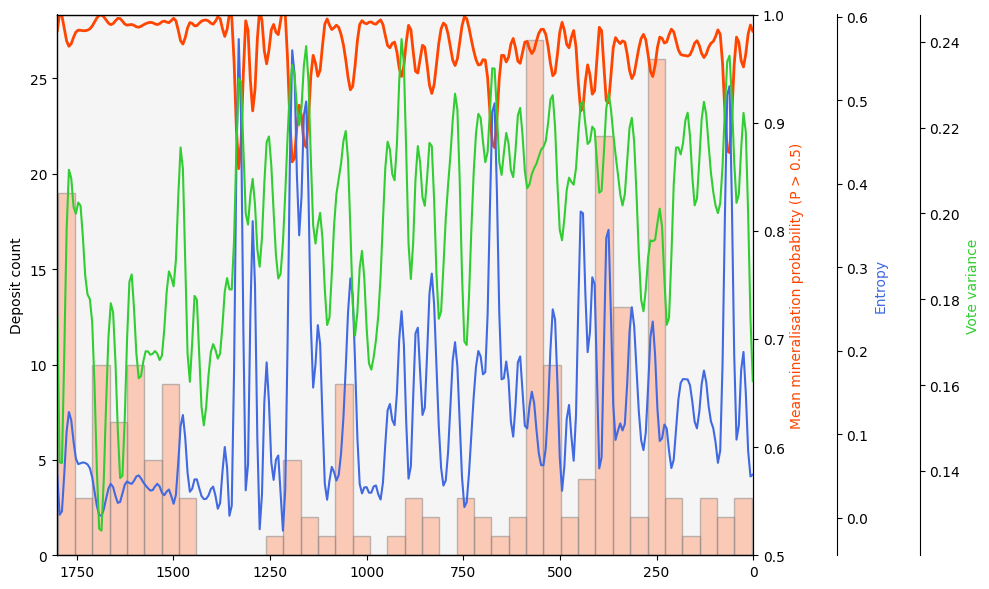

In [14]:
coastline_entropy_high_mean_age = coastline_prob_high.groupby("age (Ma)")["entropy"].mean().reset_index()
coastline_vote_var_high_mean_age = coastline_prob_high.groupby("age (Ma)")["vote_variance"].mean().reset_index()

# Sort by age to ensure correct ordering
coastline_entropy_high_mean_age = coastline_entropy_high_mean_age.sort_values("age (Ma)")
coastline_vote_var_high_mean_age = coastline_vote_var_high_mean_age.sort_values("age (Ma)")

ages_high = coastline_entropy_high_mean_age["age (Ma)"].values.reshape(-1, 1)
entropies_high = coastline_entropy_high_mean_age["entropy"].values.reshape(-1, 1)
vote_vars_high = coastline_vote_var_high_mean_age["vote_variance"].values.reshape(-1, 1)

# Smooth the curves
ages_high_smooth, entropies_high_smooth = smooth_curve(ages_high, entropies_high)
_, vote_vars_high_smooth = smooth_curve(ages_high, vote_vars_high)

# Set up plot with dual y-axes
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.set_facecolor("whitesmoke")

# Plot histogram
ax1.hist(deposit_coords_recon["age (Ma)"], bins=40, orientation="vertical", color="LightSalmon", alpha=0.5, edgecolor="gray")
ax1.set_ylabel("Deposit count")

# Create secondary y-axis
ax2 = ax1.twinx()

# Plot smoothed probability line
ax2.plot(ages_high_smooth, probs_high_smooth, color="orangered", linewidth=2)
ax2.set_xlim(1801, 0)
ax2.set_ylim(0.5, 1)
ax2.set_xlabel("Age (Ma)")
ax2.set_ylabel("Mean mineralisation probability (P > 0.5)", color="orangered")

ax3 = ax1.twinx()
ax3.spines["right"].set_position(("outward", 60))  # shift third axis to the right
ax3.plot(ages_high_smooth, entropies_high_smooth,
         linestyle="-", color="royalblue", label="Entropy")
ax3.set_ylabel("Entropy", color="royalblue")

ax4 = ax1.twinx()
ax4.spines["right"].set_position(("outward", 120))  # shift fourth axis to the right
ax4.plot(ages_high_smooth, vote_vars_high_smooth,
         linestyle="-", color="limegreen", label="Vote variance")
ax4.set_ylabel("Vote variance", color="limegreen")
    
plt.tight_layout()
plt.show()

In [25]:
def plot_entropy_votevar_high():
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_facecolor("whitesmoke")

    # Histogram
    ax1.hist(deposit_coords_recon["age (Ma)"], bins=40,
             color="LightSalmon", alpha=0.5, edgecolor="gray")
    ax1.set_ylabel("Deposit count")

    # Probability axis
    ax2 = ax1.twinx()
    ax2.plot(ages_high_smooth, probs_high_smooth,
             color="orangered", linewidth=2,
             label="Mineralisation probability")

    ax2.set_xlim(1801, 0)
    ax2.set_ylim(0.5, 1)
    ax2.set_xlabel("Age (Ma)")
    ax2.set_ylabel("Mean mineralisation probability (P > 0.8)", color="orangered")

    # Entropy axis
    ax3 = ax1.twinx()
    ax3.spines["right"].set_position(("outward", 60))
    ax3.plot(ages_high_smooth, entropies_high_smooth,
             color="royalblue", label="Entropy")
    ax3.set_ylabel("Entropy", color="royalblue")

    # Vote variance axis
    ax4 = ax1.twinx()
    ax4.spines["right"].set_position(("outward", 120))
    ax4.plot(ages_high_smooth, vote_vars_high_smooth,
             color="limegreen", label="Vote variance")
    ax4.set_ylabel("Vote variance", color="limegreen")

    # ✅ Combine legends (you didn’t do this yet)
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    lines4, labels4 = ax4.get_legend_handles_labels()

    ax1.legend(lines2 + lines3 + lines4,
               labels2 + labels3 + labels4,
               loc="upper left")

    plt.tight_layout()
    
    return fig

In [26]:
import os

output_dir = "Plots/entropy_vote_probability"
os.makedirs(output_dir, exist_ok=True)

fig = plot_entropy_votevar_high()

filename = os.path.join(output_dir, "entropy_vote_variance_high.png")
fig.savefig(filename, dpi=300, bbox_inches="tight")

plt.close(fig)

### Global Prospectivity Map of Porphyry Mineralisation

This code block generates global grids of probability, entropy, and vote variance for points within the present-day continental landmass by averaging their values through time. The grids are created by interpolating these point values, with the interpolation step filling gaps between measurements. We use nearest-neighbor interpolation but mask out grid cells located far from any known data points (based on grid resolution) to avoid misleading extrapolations. The final gridded datasets are saved as compressed NetCDF files.

In [15]:
if not os.path.isfile(coastline_prob_present_day_grid_filename):
    # Create probability, entropy, and vote variance grids for the points within present-day continental landmass
    for column, filename in zip(
        ["probability", "entropy", "vote_variance"],
        [
            coastline_prob_present_day_grid_filename,
            coastline_entropy_present_day_grid_filename,
            coastline_vote_variance_present_day_grid_filename
        ]
    ):
        xmin, xmax, ymin, ymax = -180, 180, -90, 90

        # Create the meshes
        grid_lons = np.arange(xmin, xmax + grid_resolution, grid_resolution)
        grid_lats = np.arange(ymin, ymax + grid_resolution, grid_resolution)
        grid_mlons, grid_mlats = np.meshgrid(grid_lons, grid_lats)

        data_lons = coastline_prob_present_day["present_lon"]
        data_lats = coastline_prob_present_day["present_lat"]
        data_values = coastline_prob_present_day[column]

        # Interpolate using the nearest neighbour method
        points = np.column_stack((data_lons, data_lats))
        arr = griddata(points, data_values, (grid_mlons, grid_mlats), method="nearest")  # or "linear", "cubic"

        # Mask distant grid nodes
        tree = cKDTree(points)
        flat_grid_points = np.column_stack((grid_mlons.ravel(), grid_mlats.ravel()))
        distances, _ = tree.query(flat_grid_points, k=1)

        mask = distances > grid_resolution
        arr.ravel()[mask] = np.nan  # Mask out distant nodes        

        # Create the dataset
        dset = xr.Dataset(
            data_vars={
                "z": (("lat", "lon"), arr),
            },
            coords={
                "lon": grid_lons,
                "lat": grid_lats,
            },
        )

        # Set projection info
        dset.rio.write_crs(4326, inplace=True)

        # Save as NetCDF
        dset.to_netcdf(
            filename,
            encoding={
                "z": {
                    "zlib": True,
                    "dtype": "float32",
                }
            },
        )

This cell generates an interactive probability map that displays mineralisation probability, entropy, and vote variance for points within the present-day continental landmasses, alongside known mineral occurrences. It also plots seafloor age and plate boundaries, including mid-ocean ridges and transform faults. The visualisation highlights spatial patterns—showing how mineralisation probability relates to tectonic features—and temporal evolution, illustrating how favourable conditions and identified potential areas align with known mineral occurrences.

In [16]:
# if not os.path.isfile(coastline_prob_present_day_grid_filename):
#     # Create probability, entropy, and vote variance grids for the points within present-day continental landmass
#     for column, filename in zip(
#         ["probability", "entropy", "vote_variance"],
#         [
#             coastline_prob_present_day_grid_filename,
#             coastline_entropy_present_day_grid_filename,
#             coastline_vote_variance_present_day_grid_filename
#         ]
#     ):
#         xmin, xmax, ymin, ymax = -180, 180, -90, 90

#         # Create the meshes
#         grid_lons = np.arange(xmin, xmax + 2, 2)
#         grid_lats = np.arange(ymin, ymax + 2, 2)
#         grid_mlons, grid_mlats = np.meshgrid(grid_lons, grid_lats)

#         data_lons = coastline_prob_present_day["present_lon"]
#         data_lats = coastline_prob_present_day["present_lat"]
#         data_values = coastline_prob_present_day[column]

#         # Interpolate using the nearest neighbour method
#         points = np.column_stack((data_lons, data_lats))
#         arr = griddata(points, data_values, (grid_mlons, grid_mlats), method="nearest")  # or "linear", "cubic"

#         # Mask distant grid nodes
#         tree = cKDTree(points)
#         flat_grid_points = np.column_stack((grid_mlons.ravel(), grid_mlats.ravel()))
#         distances, _ = tree.query(flat_grid_points, k=1)

#         mask = distances > 2
#         arr.ravel()[mask] = np.nan  # Mask out distant nodes        

#         # Create the dataset
#         dset = xr.Dataset(
#             data_vars={
#                 "z": (("lat", "lon"), arr),
#             },
#             coords={
#                 "lon": grid_lons,
#                 "lat": grid_lats,
#             },
#         )

#         # Set projection info
#         dset.rio.write_crs(4326, inplace=True)

#         # Save as NetCDF
#         dset.to_netcdf(
#             filename,
#             encoding={
#                 "z": {
#                     "zlib": True,
#                     "dtype": "float32",
#                 }
#             },
#         )

In [17]:
deposit_coords_recon_all = pd.read_csv(deposit_coords_recon_all_filename)
time = 0

gplot.time = time

deposit_coords_recon_t = deposit_coords_recon_all[[f"lon_{time}", f"lat_{time}", "weight"]]
deposit_coords_recon_t = deposit_coords_recon_t.dropna()
    
agegrid_filename =  "Cao2024_SEAFLOOR_AGE_grid_0.00Ma.nc"
agegrid_file = os.path.join(agegrid_dir, agegrid_filename)    
agegrid = gplately.grids.read_netcdf_grid(agegrid_file)

map_types = ["Probability", "Entropy", "Vote Variance"]

@interact
def show_map(map_type=map_types):
    # Load the appropriate raster data based on the selected map type
    if map_type==map_types[0]:
        raster = Raster(coastline_prob_present_day_grid_filename)
        raster.data *= 100.0
    elif map_type==map_types[1]:
        raster = Raster(coastline_entropy_present_day_grid_filename)
    elif map_type==map_types[2]:
        raster = Raster(coastline_vote_variance_present_day_grid_filename)

    fig = plt.figure(figsize=(16, 12))
    ax = fig.add_axes(
        [0.1, 0.1, 0.8, 0.8],
        projection=projection,
        facecolor=(plt.cm.colors.to_rgba("darkgray", alpha=0.5)),
    )

    # Create axes for colourbars
    cax_grd = fig.add_axes([0.1, 0.1, 0.35, 0.02])
    cax_bg = fig.add_axes([0.55, 0.1, 0.35, 0.02])

    # Plot seafloor age as background
    bg = gplot.plot_grid(ax, agegrid.data, cmap=ccm.lapaz_r, vmin=0, vmax=230, alpha=0.7, zorder=1)
    # Plot continental areas in dark grey
    gplot.plot_coastlines(ax, facecolor="darkgray", edgecolor="none", zorder=2)
    # Plot plate motion vectors (arrows showing plate movement direction)
    gplot.plot_plate_motion_vectors(ax, spacingX=10, spacingY=10, normalise=True, alpha=0.1, zorder=3)

    # Plot the raster data based on the selected map type
    # This will display the mineralisation probability, entropy, or vote variance
    if map_type==map_types[0]:
        # grd = raster.imshow(ax=ax, cmap=ccm.hawaii_r, vmin=0, vmax=100, alpha=0.9, zorder=4)
        grd = raster.imshow(ax=ax, cmap=ccm.hawaii_r, vmin=50, vmax=100, alpha=0.9, zorder=4)
    elif map_type==map_types[1]:
        grd = raster.imshow(ax=ax, cmap=ccm.hawaii_r, vmin=0, vmax=1, alpha=0.9, zorder=4)
    elif map_type==map_types[2]:
        grd = raster.imshow(ax=ax, cmap=ccm.hawaii_r, vmin=0, vmax=0.25, alpha=0.9, zorder=4)

    gplot.plot_ridges(ax, color="dimgray", linewidth=1.5, zorder=5)
    gplot.plot_transforms(ax, color="dimgray", linewidth=1.5, zorder=5)
    gplot.plot_trenches(ax, color="k", alpha=0.3, zorder=6)
    gplot.plot_subduction_teeth(ax, spacing=0.05, color="k", alpha=0.3, zorder=7)

    # Plot reconstructed mineral occurrences
    sc1 = ax.scatter(
        deposit_coords_recon_t[f"lon_{time}"],
        deposit_coords_recon_t[f"lat_{time}"],
        transform=ccrs.PlateCarree(),
        marker="o",
        facecolor="yellow",
        edgecolor="black",
        s = [w * 10 for w in deposit_coords_recon_t["weight"]],
        alpha=0.3,
        zorder=8
    )

    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, x_inline=False, linewidth=1, color="gray", alpha=0.3, linestyle="--", zorder=9)

    ax.text(0.49,-0.03, "60°E", transform=ax.transAxes, fontsize=16)
    ax.text(0.46,-0.03, "0°", transform=ax.transAxes, fontsize=16)
    ax.text(0.40,-0.025, "60°W", transform=ax.transAxes, fontsize=16)

    gl.top_labels=False
    gl.bottom_labels=False

    gl.xlabel_style = {"size": 16}
    gl.ylabel_style = {"size": 16}

    # Add a colourbar for the mineralisation probability, entropy, or vote variance
    cbar_grd = fig.colorbar(grd, cax=cax_grd, orientation="horizontal")
    if map_type==map_types[0]:
        cbar_grd.set_label("Mineralisation Probability", fontsize=16, labelpad=10)
    elif map_type==map_types[1]:
        cbar_grd.set_label("Entropy", fontsize=16, labelpad=10)
    elif map_type==map_types[2]:
        cbar_grd.set_label("Vote Variance", fontsize=16, labelpad=10)
    cbar_grd.ax.tick_params(labelsize=16)

    # Add a colourbar for seafloor age
    cbar_bg = fig.colorbar(bg, cax=cax_bg, orientation="horizontal", extend="max")
    cbar_bg.set_label("Seafloor Age (Ma)", fontsize=16, labelpad=10)
    cbar_bg.set_ticks([0, 50, 100, 150, 200])
    cbar_bg.ax.tick_params(labelsize=16)

    # Dummy handle to trigger custom handler
    trench_handle = Line2D([], [], color="black")
    
    # Add custom handles
    custom_handles = [
        Patch(facecolor="darkgray", edgecolor="none"),
        trench_handle,
        Line2D([0], [0], color="dimgray", lw=2),
        Line2D([0], [0], marker="o", markerfacecolor="yellow", markeredgecolor="black", markersize=15, linestyle="None"),
    ]
    custom_labels = [
        "Continental Crust",
        "Trench Lines",
        "Mid-Ocean Ridges/\nTransform Faults",
        "Mineral Occurrences",
    ]

    # Draw legend
    ax.legend(custom_handles, custom_labels, fontsize=16, loc="lower left", bbox_to_anchor=(0, -0.2),
              handler_map={trench_handle: HandlerTrenchLine()})

#     ax.set_title("Global Prospectivity Map of Porphyry Mineralisation", fontsize=25, y=1.04)

    plt.show()

interactive(children=(Dropdown(description='map_type', options=('Probability', 'Entropy', 'Vote Variance'), va…